# Attention-Enhanced HybridSN for Hyperspectral Image Classification




In [ ]:
!pip install -q scipy scikit-learn spectral gradio seaborn tqdm torchsummary umap-learn --upgrade


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.2/215.2 kB 15.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 75.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 4.0 MB/s eta 0:00:00


In [ ]:
import os
import io
import time
import gc
import json
import random
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, cohen_kappa_score, confusion_matrix,
    classification_report, precision_recall_fscore_support
)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:
#Reproducibility — fix all random seeds

SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)

    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except TypeError:

        torch.use_deterministic_algorithms(True)

set_seed(SEED)
print(f"Random seed fixed at {SEED}")

import subprocess
try:
    gpu_info = subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version,memory.total",
                                "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()
    print(f"GPU: {gpu_info}")
except Exception as e:
    print(f"Could not query GPU: {e}")

print(f"torch: {torch.__version__} | cuda: {torch.version.cuda} | "
      f"cudnn: {torch.backends.cudnn.version()} | numpy: {np.__version__}")

Random seed fixed at 42
GPU: Tesla T4, 580.82.07, 15360 MiB
torch: 2.11.0+cu128 | cuda: 12.8 | cudnn: 91900 | numpy: 2.1.3


In [ ]:
#Device configuration — automatically use GPU if available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA capability: {torch.cuda.get_device_capability(0)}")
    print(f"Total memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("WARNING: No GPU detected. Go to Runtime > Change runtime type > GPU for faster training.")


Using device: cuda
GPU: Tesla T4
CUDA capability: (7, 5)
Total memory: 15.64 GB


In [ ]:
#Mount Google Drive (datasets and outputs live here)
from google.colab import drive
drive.mount('/content/drive')

#Root folders
DRIVE_ROOT = "/content/drive/MyDrive/HybridSN_Thesis"
DATA_DIR = f"{DRIVE_ROOT}/datasets"
OUTPUT_DIR = f"{DRIVE_ROOT}/outputs"
MODEL_DIR = f"{OUTPUT_DIR}/models"
FIGURE_DIR = f"{OUTPUT_DIR}/figures"
REPORT_DIR = f"{OUTPUT_DIR}/reports"

for d in [DATA_DIR, OUTPUT_DIR, MODEL_DIR, FIGURE_DIR, REPORT_DIR]:
    os.makedirs(d, exist_ok=True)

print("Directory structure ready:")
for d in [DATA_DIR, OUTPUT_DIR, MODEL_DIR, FIGURE_DIR, REPORT_DIR]:
    print(" -", d)


Mounted at /content/drive
Directory structure ready:
 - /content/drive/MyDrive/HybridSN_Thesis/datasets
 - /content/drive/MyDrive/HybridSN_Thesis/outputs
 - /content/drive/MyDrive/HybridSN_Thesis/outputs/models
 - /content/drive/MyDrive/HybridSN_Thesis/outputs/figures
 - /content/drive/MyDrive/HybridSN_Thesis/outputs/reports


## Section 2 — Dataset Loading



In [ ]:
DATASET_REGISTRY = {
    "Pavia University": {
        "folder": "pavia_university",
        "image_file": "PaviaU.mat",
        "gt_file": "PaviaU_gt.mat",
        "image_key": "paviaU",
        "gt_key": "paviaU_gt",
        "class_names": [
            "Background", "Asphalt", "Meadows", "Gravel", "Trees",
            "Painted metal sheets", "Bare Soil", "Bitumen",
            "Self-Blocking Bricks", "Shadows"
        ],
        "rgb_bands": (55, 33, 13),
        "image_url": "http://www.ehu.eus/ccwintco/uploads/e/ee/PaviaU.mat",
        "gt_url": "http://www.ehu.eus/ccwintco/uploads/5/50/PaviaU_gt.mat",
    },
    "Salinas Scene": {
        "folder": "salinas",
        "image_file": "Salinas_corrected.mat",
        "gt_file": "Salinas_gt.mat",
        "image_key": "salinas_corrected",
        "gt_key": "salinas_gt",
        "class_names": [
            "Background", "Brocoli_green_weeds_1", "Brocoli_green_weeds_2", "Fallow",
            "Fallow_rough_plow", "Fallow_smooth", "Stubble", "Celery",
            "Grapes_untrained", "Soil_vinyard_develop", "Corn_senesced_green_weeds",
            "Lettuce_romaine_4wk", "Lettuce_romaine_5wk", "Lettuce_romaine_6wk",
            "Lettuce_romaine_7wk", "Vinyard_untrained", "Vinyard_vertical_trellis"
        ],
        "rgb_bands": (43, 21, 11),
        "image_url": "http://www.ehu.eus/ccwintco/uploads/a/a3/Salinas_corrected.mat",
        "gt_url": "http://www.ehu.eus/ccwintco/uploads/f/fa/Salinas_gt.mat",
    },
}

print("Registered datasets:", list(DATASET_REGISTRY.keys()))


Registered datasets: ['Pavia University', 'Salinas Scene']


In [ ]:
#Downloading Dataset
import urllib.request

def download_dataset_files(dataset_name: str, data_dir: str = DATA_DIR, force: bool = False):
    cfg = DATASET_REGISTRY[dataset_name]
    folder = Path(data_dir) / cfg["folder"]
    folder.mkdir(parents=True, exist_ok=True)

    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                      "(KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
    }

    for url_key, file_key in [("image_url", "image_file"), ("gt_url", "gt_file")]:
        dest = folder / cfg[file_key]
        if dest.exists() and not force:
            print(f"[{dataset_name}] {dest.name} already present — skipping.")
            continue
        url = cfg[url_key]
        print(f"[{dataset_name}] Downloading {dest.name} from {url} ...")
        try:
            req = urllib.request.Request(url, headers=headers)
            with urllib.request.urlopen(req, timeout=60) as resp, open(dest, "wb") as out_f:
                out_f.write(resp.read())
            size_mb = dest.stat().st_size / 1e6
            if size_mb < 0.05:  # a real .mat file is several MB — this is almost certainly an error page
                dest.unlink()
                raise ValueError(f"Downloaded file is only {size_mb*1000:.1f} KB — likely an error page, not the dataset.")
            print(f"[{dataset_name}] Saved {dest.name} ({size_mb:.1f} MB) -> {dest}")
        except Exception as e:
            print(f"[{dataset_name}] FAILED to download {dest.name}: {e}\n"
                  f"  You can download it manually from {url} and place it at {dest}")

def download_all_datasets(force: bool = False):
    for name in DATASET_REGISTRY:
        download_dataset_files(name, force=force)

print("Download helpers ready: download_dataset_files(name), download_all_datasets()")


Download helpers ready: download_dataset_files(name), download_all_datasets()


In [ ]:
#Generic .mat loader
def load_hyperspectral_dataset(dataset_name: str, data_dir: str = DATA_DIR):

    if dataset_name not in DATASET_REGISTRY:
        raise ValueError(f"Unknown dataset '{dataset_name}'. Choose from {list(DATASET_REGISTRY.keys())}")

    cfg = DATASET_REGISTRY[dataset_name]
    folder = Path(data_dir) / cfg["folder"]
    image_path = folder / cfg["image_file"]
    gt_path = folder / cfg["gt_file"]

    if not image_path.exists() or not gt_path.exists():
        raise FileNotFoundError(
            f"Could not find .mat files for '{dataset_name}'.\n"
            f"Expected:\n  {image_path}\n  {gt_path}\n"
            f"Please upload the dataset to your Google Drive under: {folder}"
        )

    image_mat = sio.loadmat(str(image_path))
    gt_mat = sio.loadmat(str(gt_path))

    cube = image_mat[cfg["image_key"]].astype(np.float32)
    gt = gt_mat[cfg["gt_key"]].astype(np.int64)

    meta = {
        "dataset_name": dataset_name,
        "class_names": cfg["class_names"],
        "rgb_bands": cfg["rgb_bands"],
        "num_classes": int(gt.max()),
    }
    return cube, gt, meta


In [ ]:
#Dataset summary printer
def print_dataset_summary(cube, gt, meta):
    print("=" * 60)
    print(f"DATASET: {meta['dataset_name']}")
    print("=" * 60)
    print(f"Cube shape (H x W x Bands) : {cube.shape}")
    print(f"Number of spectral bands   : {cube.shape[-1]}")
    print(f"Number of classes (excl. bg): {meta['num_classes']}")
    print(f"Ground truth shape          : {gt.shape}")
    print(f"Data type / range           : {cube.dtype}, min={cube.min():.2f}, max={cube.max():.2f}")
    print("-" * 60)
    print("Class distribution:")
    labels, counts = np.unique(gt, return_counts=True)
    total = gt.size
    for lbl, cnt in zip(labels, counts):
        name = meta["class_names"][lbl] if lbl < len(meta["class_names"]) else f"Class {lbl}"
        print(f"  [{lbl:2d}] {name:<32s}: {cnt:7d} px  ({100*cnt/total:5.2f}%)")
    print("=" * 60)




######################################################################
Loading: Pavia University
######################################################################
[Pavia University] PaviaU.mat already present — skipping.
[Pavia University] PaviaU_gt.mat already present — skipping.
DATASET: Pavia University
Cube shape (H x W x Bands) : (610, 340, 103)
Number of spectral bands   : 103
Number of classes (excl. bg): 9
Ground truth shape          : (610, 340)
Data type / range           : float32, min=0.00, max=8000.00
------------------------------------------------------------
Class distribution:
  [ 0] Background                      :  164624 px  (79.38%)
  [ 1] Asphalt                         :    6631 px  ( 3.20%)
  [ 2] Meadows                         :   18649 px  ( 8.99%)
  [ 3] Gravel                          :    2099 px  ( 1.01%)
  [ 4] Trees                           :    3064 px  ( 1.48%)
  [ 5] Painted metal sheets            :    1345 px  ( 0.65%)
  [ 6] Bare Soil     

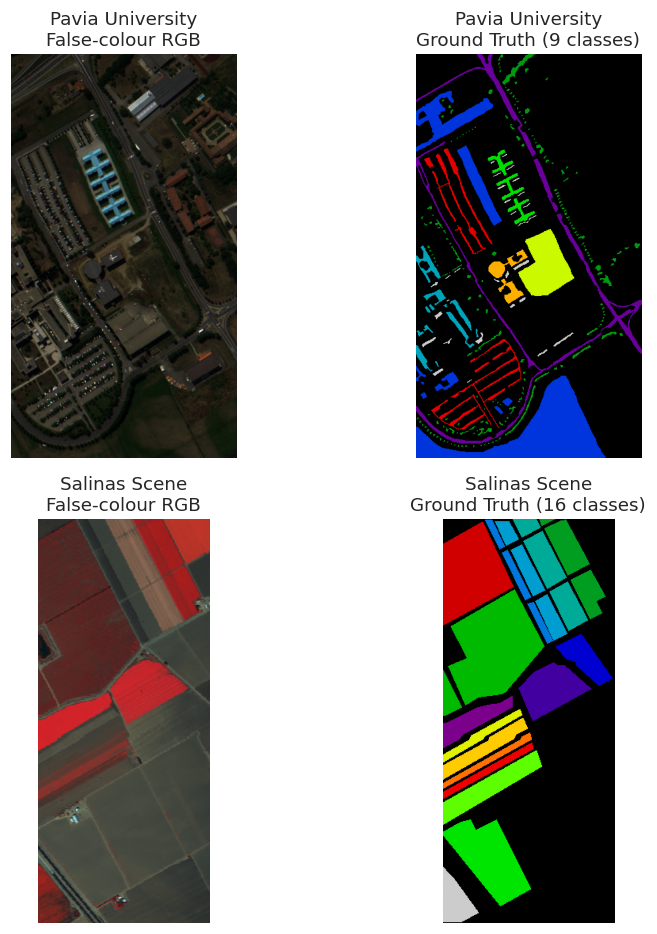

Working dataset set to: Salinas Scene


In [ ]:
#Select the dataset

LOADED_DATASETS = {}

def preview_all_datasets():
    names = list(DATASET_REGISTRY.keys())
    n = len(names)
    fig, axes = plt.subplots(n, 2, figsize=(9, 4.3 * n))
    if n == 1:
        axes = axes.reshape(1, 2)

    for row, dataset_name in enumerate(names):
        print(f"\n{'#'*70}\nLoading: {dataset_name}\n{'#'*70}")
        download_dataset_files(dataset_name)
        cube, gt, meta = load_hyperspectral_dataset(dataset_name)
        LOADED_DATASETS[dataset_name] = (cube, gt, meta)
        print_dataset_summary(cube, gt, meta)

        # --- False-colour RGB ---
        r, g, b = meta["rgb_bands"]
        rgb = cube[:, :, [min(r, cube.shape[-1]-1), min(g, cube.shape[-1]-1), min(b, cube.shape[-1]-1)]]
        rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)
        axes[row, 0].imshow(rgb)
        axes[row, 0].set_title(f"{dataset_name}\nFalse-colour RGB")
        axes[row, 0].axis("off")

        # --- Ground truth map ---
        cmap = plt.get_cmap("nipy_spectral", meta["num_classes"] + 1)
        axes[row, 1].imshow(gt, cmap=cmap, vmin=0, vmax=meta["num_classes"])
        axes[row, 1].set_title(f"{dataset_name}\nGround Truth ({meta['num_classes']} classes)")
        axes[row, 1].axis("off")

    fig.tight_layout()
    plt.show()
    return LOADED_DATASETS

LOADED_DATASETS = preview_all_datasets()



DATASET_NAME = "Salinas Scene"
cube, gt, meta = LOADED_DATASETS[DATASET_NAME]
print(f"Working dataset set to: {DATASET_NAME}")



## Section 3 — Data Preprocessing

Pipeline: noisy-band removal → normalization → PCA dimensionality reduction →
patch extraction → background removal → label encoding → train/val/test split → PyTorch `Dataset`/`DataLoader`.



In [ ]:
#1 Preprocessing hyperparameters
PATCH_SIZE = 11
N_PCA_COMPONENTS = 30
USE_PCA = True
TEST_RATIO = 0.20
VAL_RATIO = 0.10
REMOVE_NOISY_BANDS = False

print(f"PATCH_SIZE={PATCH_SIZE}, N_PCA_COMPONENTS={N_PCA_COMPONENTS if USE_PCA else 'disabled'}, "
      f"TEST_RATIO={TEST_RATIO}, VAL_RATIO={VAL_RATIO}")


PATCH_SIZE=11, N_PCA_COMPONENTS=30, TEST_RATIO=0.2, VAL_RATIO=0.1


In [ ]:
#2 Remove known noisy / water-absorption spectral bands
NOISY_BANDS = {
    "Indian Pines": [],
    "Pavia University": [],
    "Salinas Scene": [],
}

def remove_noisy_bands(cube: np.ndarray, dataset_name: str, enabled: bool = REMOVE_NOISY_BANDS):
    if not enabled:
        return cube
    bands_to_drop = NOISY_BANDS.get(dataset_name, [])
    if not bands_to_drop:
        return cube
    keep = [b for b in range(cube.shape[-1]) if b not in bands_to_drop]
    return cube[:, :, keep]

cube_clean = remove_noisy_bands(cube, DATASET_NAME)
print(f"Shape after noisy-band removal: {cube_clean.shape}")


Shape after noisy-band removal: (512, 217, 204)


In [ ]:
#3 Normalization — per-band standardization to zero mean / unit variance
def normalize_cube(cube: np.ndarray) -> np.ndarray:
    h, w, b = cube.shape
    flat = cube.reshape(-1, b)
    scaler = StandardScaler()
    flat_scaled = scaler.fit_transform(flat)
    return flat_scaled.reshape(h, w, b).astype(np.float32)

cube_norm = normalize_cube(cube_clean)
print(f"Shape after normalization: {cube_norm.shape}  "
      f"(mean={cube_norm.mean():.4f}, std={cube_norm.std():.4f})")


Shape after normalization: (512, 217, 204)  (mean=-0.0000, std=1.0000)


In [ ]:
#4 PCA — reduce spectral dimensionality while retaining spatial dimensions
def apply_pca(cube: np.ndarray, n_components: int):
    h, w, b = cube.shape
    flat = cube.reshape(-1, b)
    pca = PCA(n_components=n_components, whiten=True, random_state=SEED)
    reduced = pca.fit_transform(flat)
    reduced_cube = reduced.reshape(h, w, n_components).astype(np.float32)
    explained = pca.explained_variance_ratio_.sum()
    return reduced_cube, pca, explained

if USE_PCA:
    cube_pca, pca_model, explained_var = apply_pca(cube_norm, N_PCA_COMPONENTS)
    print(f"Shape after PCA: {cube_pca.shape}  (explained variance: {explained_var*100:.2f}%)")
else:
    cube_pca = cube_norm
    pca_model, explained_var = None, None
    print(f"PCA disabled — using all {cube_pca.shape[-1]} bands")



del cube_clean, cube_norm
gc.collect()


Shape after PCA: (512, 217, 30)  (explained variance: 99.96%)


9059

In [ ]:
#5 Patch extraction with zero-padding, and background-pixel removal
def pad_with_zeros(cube: np.ndarray, margin: int) -> np.ndarray:
    h, w, b = cube.shape
    padded = np.zeros((h + 2 * margin, w + 2 * margin, b), dtype=cube.dtype)
    padded[margin:margin + h, margin:margin + w, :] = cube
    return padded

def extract_patches(cube: np.ndarray, gt: np.ndarray, patch_size: int, remove_background: bool = True):
    margin = patch_size // 2
    padded_cube = pad_with_zeros(cube, margin)
    h, w = gt.shape

    patches, labels, coords = [], [], []
    for i in range(h):
        for j in range(w):
            label = gt[i, j]
            if remove_background and label == 0:
                continue
            patch = padded_cube[i:i + patch_size, j:j + patch_size, :]
            patches.append(patch)
            labels.append(label - 1 if remove_background else label)  # shift to 0-indexed classes
            coords.append((i, j))

    patches = np.array(patches, dtype=np.float32)
    labels = np.array(labels, dtype=np.int64)
    coords = np.array(coords, dtype=np.int64)
    return patches, labels, coords

patches, labels, coords = extract_patches(cube_pca, gt, PATCH_SIZE, remove_background=True)
print(f"Extracted patches shape: {patches.shape}")
print(f"Extracted labels shape : {labels.shape}")
print(f"Number of classes in labels: {len(np.unique(labels))}")


Extracted patches shape: (54129, 11, 11, 30)
Extracted labels shape : (54129,)
Number of classes in labels: 16


In [ ]:
#6 Label encoding sanity check
unique_labels = np.unique(labels)
assert unique_labels.min() == 0 and unique_labels.max() == len(unique_labels) - 1, \
    "Labels must be contiguous 0-indexed integers"
NUM_CLASSES = len(unique_labels)
print(f"Label encoding OK — {NUM_CLASSES} contiguous classes: {unique_labels.tolist()}")


Label encoding OK — 16 contiguous classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [ ]:
#7 Train / Validation / Test split


def spatial_block_split(patches, labels, coords, gt_shape, patch_size,
                         test_ratio, val_ratio, seed, block_size=32):

    h, w = gt_shape
    margin = patch_size // 2
    n_blocks_h = int(np.ceil(h / block_size))
    n_blocks_w = int(np.ceil(w / block_size))

    rng = np.random.RandomState(seed)
    block_ids = np.arange(n_blocks_h * n_blocks_w)
    rng.shuffle(block_ids)
    n_test = int(len(block_ids) * test_ratio)
    n_val = int(len(block_ids) * val_ratio)
    test_blocks = set(block_ids[:n_test].tolist())
    val_blocks = set(block_ids[n_test:n_test + n_val].tolist())
    train_blocks = set(block_ids[n_test + n_val:].tolist())

    ci, cj = coords[:, 0], coords[:, 1]
    block_row, block_col = ci // block_size, cj // block_size
    block_id = block_row * n_blocks_w + block_col

    row_off, col_off = ci % block_size, cj % block_size
    near_edge = (
        (row_off < margin) | (row_off >= block_size - margin) |
        (col_off < margin) | (col_off >= block_size - margin)
    )

    is_train = np.isin(block_id, list(train_blocks)) & ~near_edge
    is_val   = np.isin(block_id, list(val_blocks))   & ~near_edge
    is_test  = np.isin(block_id, list(test_blocks))  & ~near_edge

    return (patches[is_train], labels[is_train],
            patches[is_val],   labels[is_val],
            patches[is_test],  labels[is_test])

BLOCK_SIZE = 32

X_train, y_train, X_val, y_val, X_test, y_test = spatial_block_split(
    patches, labels, coords, gt.shape, PATCH_SIZE, TEST_RATIO, VAL_RATIO, SEED, BLOCK_SIZE
)

print(f"Train set: X={X_train.shape}, y={y_train.shape}")
print(f"Val set  : X={X_val.shape}, y={y_val.shape}")
print(f"Test set : X={X_test.shape}, y={y_test.shape}")
print(f"Dropped to edge buffer / unassigned blocks: "
      f"{patches.shape[0] - (len(y_train) + len(y_val) + len(y_test))}")
print(f"Classes present — train:{len(np.unique(y_train))} "
      f"val:{len(np.unique(y_val))} test:{len(np.unique(y_test))} "
      f"(dataset has {NUM_CLASSES})")


del patches, labels, coords
gc.collect()

Train set: X=(17103, 11, 11, 30), y=(17103,)
Val set  : X=(3465, 11, 11, 30), y=(3465,)
Test set : X=(5163, 11, 11, 30), y=(5163,)
Dropped to edge buffer / unassigned blocks: 28398
Classes present — train:16 val:7 test:11 (dataset has 16)


0

In [ ]:
#8 PyTorch Dataset and DataLoader
class HyperspectralPatchDataset(Dataset):
    def __init__(self, patches: np.ndarray, labels: np.ndarray):
        data = patches.transpose(0, 3, 1, 2)
        self.data = torch.from_numpy(data).unsqueeze(1).float()
        self.labels = torch.from_numpy(labels).long()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.data[idx], self.labels[idx]

BATCH_SIZE = 128

train_dataset = HyperspectralPatchDataset(X_train, y_train)
val_dataset = HyperspectralPatchDataset(X_val, y_val)
test_dataset = HyperspectralPatchDataset(X_test, y_test)

g = torch.Generator()
g.manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,num_workers=0, pin_memory=True, generator=g)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,num_workers=0, pin_memory=True)

sample_x, sample_y = next(iter(train_loader))
print(f"Train dataset size: {len(train_dataset)}")
print(f"Val dataset size  : {len(val_dataset)}")
print(f"Test dataset size : {len(test_dataset)}")
print(f"Sample batch X shape: {sample_x.shape}  (batch, 1, spectral, H, W)")
print(f"Sample batch y shape: {sample_y.shape}")

INPUT_CHANNELS = X_train.shape[-1]
print(f"INPUT_CHANNELS (spectral depth fed to Conv3d) = {INPUT_CHANNELS}")
print(f"PATCH_SIZE = {PATCH_SIZE}, NUM_CLASSES = {NUM_CLASSES}")


Train dataset size: 17103
Val dataset size  : 3465
Test dataset size : 5163
Sample batch X shape: torch.Size([128, 1, 30, 11, 11])  (batch, 1, spectral, H, W)
Sample batch y shape: torch.Size([128])
INPUT_CHANNELS (spectral depth fed to Conv3d) = 30
PATCH_SIZE = 11, NUM_CLASSES = 16


## Section 4 — Baseline Model: HybridSN



In [ ]:
# HybridSN — baseline architecture
class HybridSN(nn.Module):
    def __init__(self, input_channels: int, patch_size: int, num_classes: int):
        super().__init__()
        self.input_channels = input_channels
        self.patch_size = patch_size


        self.conv3d_1 = nn.Conv3d(1, 8, kernel_size=(7, 3, 3))
        self.conv3d_2 = nn.Conv3d(8, 16, kernel_size=(5, 3, 3))
        self.conv3d_3 = nn.Conv3d(16, 32, kernel_size=(3, 3, 3))

        with torch.no_grad():
            dummy = torch.zeros(1, 1, input_channels, patch_size, patch_size)
            dummy_out = self._forward_3d(dummy)
            _, c, d, h, w = dummy_out.shape
            self.reshaped_channels = c * d
            conv2d_in_h, conv2d_in_w = h, w

        self.conv2d = nn.Conv2d(self.reshaped_channels, 64, kernel_size=(3, 3))

        with torch.no_grad():
            dummy2d = torch.zeros(1, self.reshaped_channels, conv2d_in_h, conv2d_in_w)
            flat_dim = self.conv2d(dummy2d).numel()

        self.fc1 = nn.Linear(flat_dim, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, num_classes)
        self.dropout = nn.Dropout(0.4)

    def _forward_3d(self, x):
        x = F.relu(self.conv3d_1(x))
        x = F.relu(self.conv3d_2(x))
        x = F.relu(self.conv3d_3(x))
        return x

    def forward(self, x):
        x = self._forward_3d(x)
        b, c, d, h, w = x.shape
        x = x.reshape(b, c * d, h, w)
        x = F.relu(self.conv2d(x))
        x = x.reshape(b, -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.dropout(F.relu(self.fc2(x)))
        x = self.fc3(x)
        return x

baseline_model = HybridSN(INPUT_CHANNELS, PATCH_SIZE, NUM_CLASSES).to(DEVICE)
with torch.no_grad():
    test_out = baseline_model(sample_x.to(DEVICE))
print(f"HybridSN output shape: {test_out.shape}  (expected: [batch, {NUM_CLASSES}])")

n_params = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
print(f"HybridSN trainable parameters: {n_params:,}")


HybridSN output shape: torch.Size([128, 16])  (expected: [batch, 16])
HybridSN trainable parameters: 534,656


## Section 5 — Attention-Enhanced HybridSN



In [ ]:
#SE Attention (Squeeze-and-Excitation)
class SEAttention(nn.Module):
    def __init__(self, channels: int, reduction: int = 8):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, hidden, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels, bias=False),
            nn.Sigmoid(),
        )
        self.last_attention = None

    def forward(self, x):
        b, c, h, w = x.shape
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        self.last_attention = y.detach()
        return x * y


In [ ]:
#CBAM — Convolutional Block Attention Module (channel + spatial)
class CBAMChannelAttention(nn.Module):
    def __init__(self, channels: int, reduction: int = 8):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.mlp = nn.Sequential(
            nn.Linear(channels, hidden, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels, bias=False),
        )
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

    def forward(self, x):
        b, c, h, w = x.shape
        avg_out = self.mlp(self.avg_pool(x).view(b, c))
        max_out = self.mlp(self.max_pool(x).view(b, c))
        gate = torch.sigmoid(avg_out + max_out).view(b, c, 1, 1)
        return x * gate

class CBAMSpatialAttention(nn.Module):
    def __init__(self, kernel_size: int = 7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=kernel_size // 2, bias=False)

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        gate = torch.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))
        return x * gate

class CBAM(nn.Module):
    def __init__(self, channels: int, reduction: int = 8, spatial_kernel: int = 7):
        super().__init__()
        self.channel_att = CBAMChannelAttention(channels, reduction)
        self.spatial_att = CBAMSpatialAttention(spatial_kernel)
        self.last_attention = None

    def forward(self, x):
        x = self.channel_att(x)
        spatial_gate_input = x
        x = self.spatial_att(x)
        avg_out = torch.mean(spatial_gate_input, dim=1, keepdim=True)
        max_out, _ = torch.max(spatial_gate_input, dim=1, keepdim=True)
        self.last_attention = torch.sigmoid(
            self.spatial_att.conv(torch.cat([avg_out, max_out], dim=1))
        ).detach()
        return x


In [ ]:
#Spectral Self-Attention — scaled dot-product attention across channels
class SpectralSelfAttention(nn.Module):

    def __init__(self, channels: int, spatial_dim: int, embed_dim: int = 64):
        super().__init__()
        self.channels = channels
        self.query = nn.Linear(spatial_dim, embed_dim)
        self.key = nn.Linear(spatial_dim, embed_dim)
        self.value = nn.Linear(spatial_dim, spatial_dim)
        self.scale = embed_dim ** 0.5
        self.last_attention = None

    def forward(self, x):
        b, c, h, w = x.shape
        tokens = x.view(b, c, h * w)
        q = self.query(tokens)
        k = self.key(tokens)
        v = self.value(tokens)

        attn_scores = torch.bmm(q, k.transpose(1, 2)) / self.scale
        attn_weights = F.softmax(attn_scores, dim=-1)
        self.last_attention = attn_weights.detach()

        out = torch.bmm(attn_weights, v)
        out = out.view(b, c, h, w)
        return x + out


In [ ]:
#Attention factory — builds the requested module (or an identity passthrough for the baseline)
class IdentityAttention(nn.Module):

    def __init__(self, *args, **kwargs):
        super().__init__()
        self.last_attention = None

    def forward(self, x):
        return x

def build_attention_module(attention_type: str, channels: int, spatial_dim: int = None):

    attention_type = attention_type.lower()
    if attention_type == "none":
        return IdentityAttention()
    elif attention_type == "se":
        return SEAttention(channels)
    elif attention_type == "cbam":
        return CBAM(channels)
    elif attention_type == "spectral":
        assert spatial_dim is not None, "spatial_dim (H*W) required for spectral self-attention"
        return SpectralSelfAttention(channels, spatial_dim)
    else:
        raise ValueError(f"Unknown attention_type '{attention_type}'. Choose from: none, se, cbam, spectral")


In [ ]:
#Attention-Enhanced HybridSN
class AttentionHybridSN(nn.Module):
    def __init__(self, input_channels: int, patch_size: int, num_classes: int, attention_type: str = "se"):
        super().__init__()
        self.attention_type = attention_type

        #3D CNN block
        self.conv3d_1 = nn.Conv3d(1, 8, kernel_size=(7, 3, 3))
        self.conv3d_2 = nn.Conv3d(8, 16, kernel_size=(5, 3, 3))
        self.conv3d_3 = nn.Conv3d(16, 32, kernel_size=(3, 3, 3))

        with torch.no_grad():
            dummy = torch.zeros(1, 1, input_channels, patch_size, patch_size)
            dummy_out = self._forward_3d(dummy)
            _, c, d, h, w = dummy_out.shape
            self.reshaped_channels = c * d
            spatial_dim = h * w

        #Attention module
        self.attention = build_attention_module(attention_type, self.reshaped_channels, spatial_dim)

        #2D CNN block
        self.conv2d = nn.Conv2d(self.reshaped_channels, 64, kernel_size=(3, 3))

        with torch.no_grad():
            dummy2d = torch.zeros(1, self.reshaped_channels, h, w)
            flat_dim = self.conv2d(dummy2d).numel()

        #Fully connected classifier
        self.fc1 = nn.Linear(flat_dim, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, num_classes)
        self.dropout = nn.Dropout(0.4)

    def _forward_3d(self, x):
        x = F.relu(self.conv3d_1(x))
        x = F.relu(self.conv3d_2(x))
        x = F.relu(self.conv3d_3(x))
        return x

    def forward(self, x):
        x = self._forward_3d(x)
        b, c, d, h, w = x.shape
        x = x.reshape(b, c * d, h, w)
        x = self.attention(x)
        x = F.relu(self.conv2d(x))
        x = x.reshape(b, -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.dropout(F.relu(self.fc2(x)))
        x = self.fc3(x)
        return x

    def get_last_attention_map(self):
        return self.attention.last_attention

for att_type in ["none", "se", "cbam", "spectral"]:
    m = AttentionHybridSN(INPUT_CHANNELS, PATCH_SIZE, NUM_CLASSES, attention_type=att_type).to(DEVICE)
    with torch.no_grad():
        out = m(sample_x.to(DEVICE))
    n_p = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"attention_type='{att_type:8s}' -> output {tuple(out.shape)}, params={n_p:,}")


ATTENTION_TYPE = "cbam"   #change to 'cbam' or 'spectral' to switch mechanisms
attention_model = AttentionHybridSN(INPUT_CHANNELS, PATCH_SIZE, NUM_CLASSES, attention_type=ATTENTION_TYPE).to(DEVICE)
print(f"\nActive attention mechanism for training: '{ATTENTION_TYPE}'")


attention_type='none    ' -> output (128, 16), params=534,656
attention_type='se      ' -> output (128, 16), params=617,600
attention_type='cbam    ' -> output (128, 16), params=617,698
attention_type='spectral' -> output (128, 16), params=538,634

Active attention mechanism for training: 'cbam'


## Section 6 — Training



In [ ]:
#Shared training hyperparameters
TRAIN_CONFIG = {
    "epochs": 50,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "early_stopping_patience": 7,
    "scheduler_patience": 3,
    "scheduler_factor": 0.5,
}
print(TRAIN_CONFIG)


{'epochs': 50, 'lr': 0.001, 'weight_decay': 0.0001, 'early_stopping_patience': 7, 'scheduler_patience': 3, 'scheduler_factor': 0.5}


In [ ]:
class EarlyStopping:
    def __init__(self, patience: int = 15, min_delta: float = 1e-4, smooth_window: int = 3):
        self.patience = patience
        self.min_delta = min_delta
        self.smooth_window = smooth_window
        self.best_loss = np.inf
        self.best_acc = -1.0
        self.loss_history = []
        self.counter = 0
        self.should_stop = False

    def step(self, val_loss: float, val_acc: float) -> bool:
        self.loss_history.append(val_loss)
        smoothed_loss = sum(self.loss_history[-self.smooth_window:]) / len(self.loss_history[-self.smooth_window:])

        improved = (val_acc > self.best_acc + self.min_delta) or (
            abs(val_acc - self.best_acc) <= self.min_delta
            and smoothed_loss < (self.best_loss - self.min_delta)
        )

        if improved:
            self.best_acc = val_acc
            self.best_loss = smoothed_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return improved

In [ ]:
# evaluate epoch
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if is_train:
                optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * xb.size(0)
            preds = logits.argmax(dim=1)
            correct += (preds == yb).sum().item()
            total += xb.size(0)

    return total_loss / total, correct / total


In [ ]:
# Full training loop with LR scheduling, early stopping, and checkpointing
def train_model(model, model_name: str, train_loader, val_loader, config: dict, checkpoint_dir: str = MODEL_DIR):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=config["scheduler_factor"], patience=config["scheduler_patience"]
    )
    early_stopper = EarlyStopping(patience=config["early_stopping_patience"])

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    checkpoint_path = os.path.join(checkpoint_dir, f"{model_name}_{DATASET_NAME.replace(' ', '_')}.pth")

    start_time = time.time()
    for epoch in range(1, config["epochs"] + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)
        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        improved = early_stopper.step(val_loss, val_acc)
        if improved:
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "val_loss": val_loss,
                "val_acc": val_acc,
                "config": config,
            }, checkpoint_path)

        current_lr = optimizer.param_groups[0]["lr"]
        print(f"[{model_name}] Epoch {epoch:3d}/{config['epochs']} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | lr={current_lr:.2e}"
              f"{'  *checkpoint*' if improved else ''}")

        if early_stopper.should_stop:
            print(f"Early stopping triggered at epoch {epoch} (no improvement for "
                  f"{config['early_stopping_patience']} epochs).")
            break

    train_time_sec = time.time() - start_time
    print(f"\n[{model_name}] Training complete in {train_time_sec:.1f}s. "
          f"Best val_acc={early_stopper.best_acc:.4f} (smoothed val_loss={early_stopper.best_loss:.4f}). "
          f"Checkpoint saved to: {checkpoint_path}")


    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])

    return history, train_time_sec, checkpoint_path


In [ ]:
#Train the baseline HybridSN
set_seed(SEED)
g.manual_seed(SEED)
baseline_model = HybridSN(INPUT_CHANNELS, PATCH_SIZE, NUM_CLASSES).to(DEVICE)
history_baseline, time_baseline, ckpt_baseline = train_model(
    baseline_model, "HybridSN", train_loader, val_loader, TRAIN_CONFIG
)
gc.collect()
torch.cuda.empty_cache()





[HybridSN] Epoch   1/50 | train_loss=0.7575 train_acc=0.7339 | val_loss=0.6621 val_acc=0.8846 | lr=1.00e-03  *checkpoint*
[HybridSN] Epoch   2/50 | train_loss=0.0828 train_acc=0.9724 | val_loss=0.8244 val_acc=0.9218 | lr=1.00e-03  *checkpoint*
[HybridSN] Epoch   3/50 | train_loss=0.0436 train_acc=0.9861 | val_loss=0.6541 val_acc=0.9120 | lr=1.00e-03
[HybridSN] Epoch   4/50 | train_loss=0.0182 train_acc=0.9944 | val_loss=1.0817 val_acc=0.8973 | lr=1.00e-03
[HybridSN] Epoch   5/50 | train_loss=0.0186 train_acc=0.9953 | val_loss=0.6789 val_acc=0.9322 | lr=1.00e-03  *checkpoint*
[HybridSN] Epoch   6/50 | train_loss=0.0208 train_acc=0.9943 | val_loss=1.9321 val_acc=0.8762 | lr=1.00e-03
[HybridSN] Epoch   7/50 | train_loss=0.0116 train_acc=0.9966 | val_loss=1.8621 val_acc=0.8854 | lr=5.00e-04
[HybridSN] Epoch   8/50 | train_loss=0.0029 train_acc=0.9991 | val_loss=1.7223 val_acc=0.8854 | lr=5.00e-04
[HybridSN] Epoch   9/50 | train_loss=0.0014 train_acc=0.9995 | val_loss=1.8289 val_acc=0.8889 

In [ ]:
#Train the Attention-Enhanced HybridSN for each attention mechanism (SE, CBAM, Spectral)
ATTENTION_TYPES = ["se", "cbam", "spectral"]

results = {}
trained_models = {}

for att_type in ATTENTION_TYPES:
    print(f"\n{'='*70}\nTraining attention_type='{att_type}'\n{'='*70}")
    set_seed(SEED)
    g.manual_seed(SEED)
    model = AttentionHybridSN(INPUT_CHANNELS, PATCH_SIZE, NUM_CLASSES, attention_type=att_type).to(DEVICE)
    history, train_time, ckpt_path = train_model(model, f"AttentionHybridSN_{att_type}", train_loader, val_loader, TRAIN_CONFIG)

    results[att_type] = {
        "history": history,
        "train_time": train_time,
        "ckpt_path": ckpt_path,
        "best_val_acc": max(history["val_acc"]),
        "best_val_loss": min(history["val_loss"]),
    }
    trained_models[att_type] = model

    gc.collect()
    torch.cuda.empty_cache()

print(f"\n{'='*70}")
print("Summary of all attention types:")
for att_type, r in results.items():
    print(f"  {att_type:8s} | best_val_acc={r['best_val_acc']:.4f} | "
          f"best_val_loss={r['best_val_loss']:.4f} | time={r['train_time']:.1f}s")



Training attention_type='se'
[AttentionHybridSN_se] Epoch   1/50 | train_loss=0.7492 train_acc=0.7341 | val_loss=0.6375 val_acc=0.8620 | lr=1.00e-03  *checkpoint*
[AttentionHybridSN_se] Epoch   2/50 | train_loss=0.0716 train_acc=0.9767 | val_loss=0.5950 val_acc=0.9270 | lr=1.00e-03  *checkpoint*
[AttentionHybridSN_se] Epoch   3/50 | train_loss=0.0325 train_acc=0.9897 | val_loss=0.7386 val_acc=0.9051 | lr=1.00e-03
[AttentionHybridSN_se] Epoch   4/50 | train_loss=0.0174 train_acc=0.9957 | val_loss=0.4703 val_acc=0.9339 | lr=1.00e-03  *checkpoint*
[AttentionHybridSN_se] Epoch   5/50 | train_loss=0.0086 train_acc=0.9977 | val_loss=0.6530 val_acc=0.9296 | lr=1.00e-03
[AttentionHybridSN_se] Epoch   6/50 | train_loss=0.0133 train_acc=0.9960 | val_loss=0.6905 val_acc=0.9328 | lr=1.00e-03
[AttentionHybridSN_se] Epoch   7/50 | train_loss=0.0128 train_acc=0.9973 | val_loss=0.4136 val_acc=0.9328 | lr=1.00e-03
[AttentionHybridSN_se] Epoch   8/50 | train_loss=0.0144 train_acc=0.9962 | val_loss=0.69

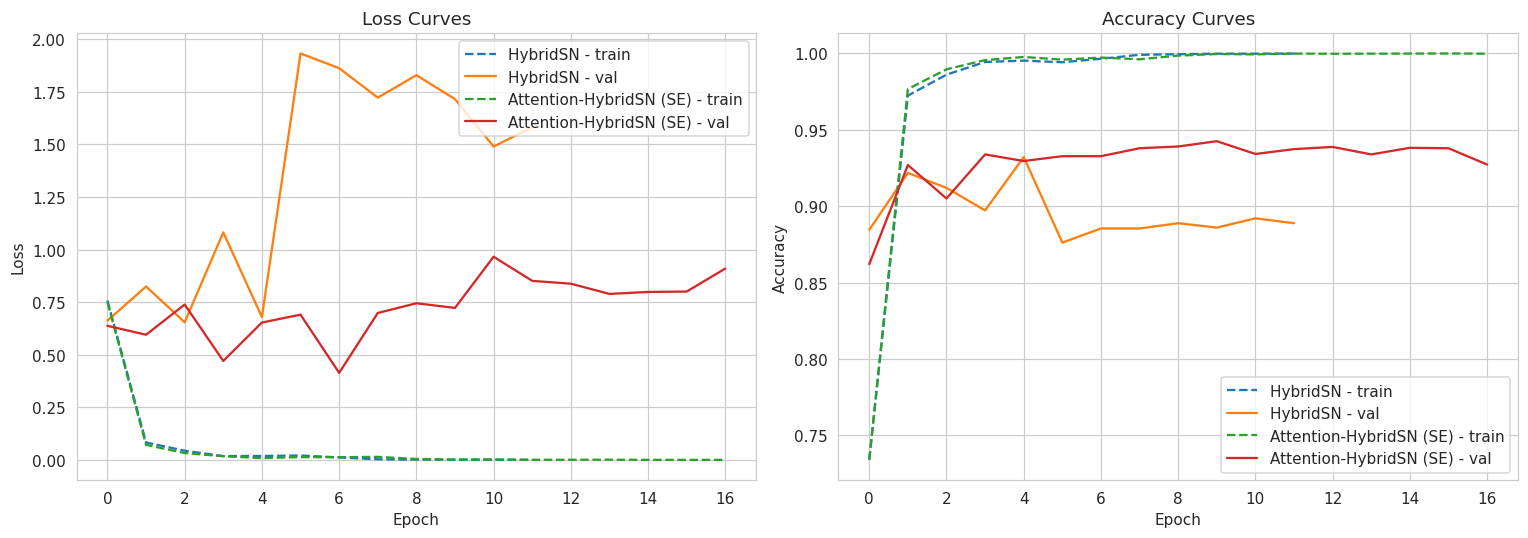

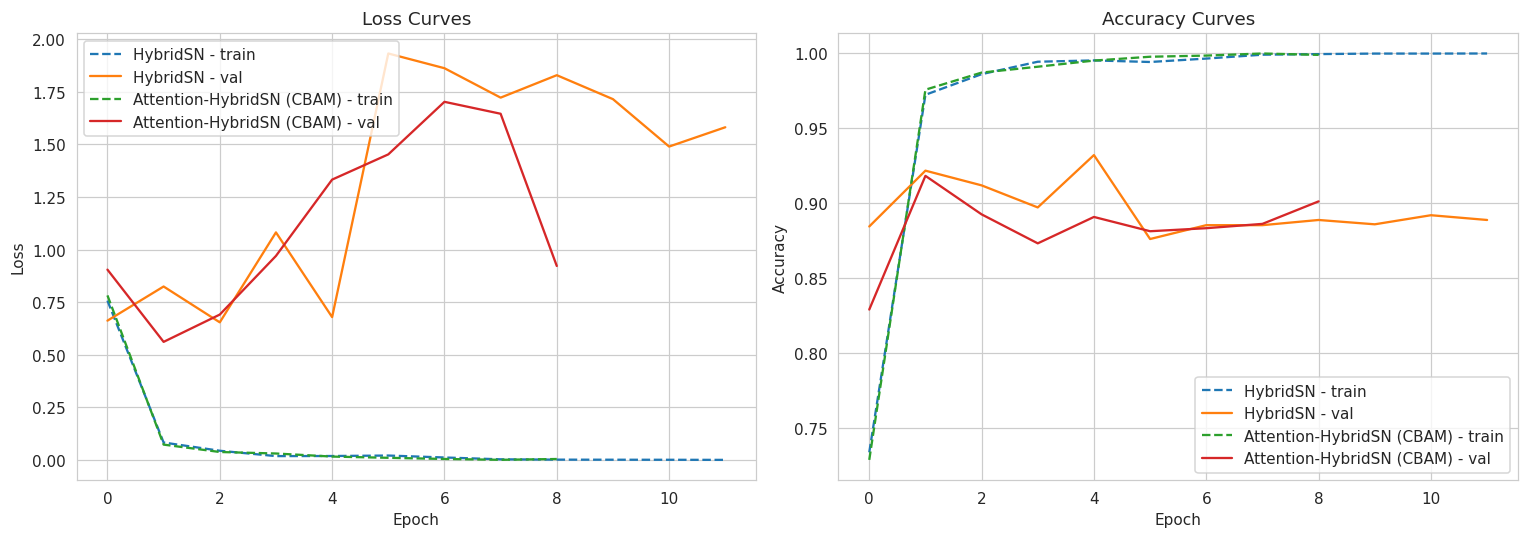

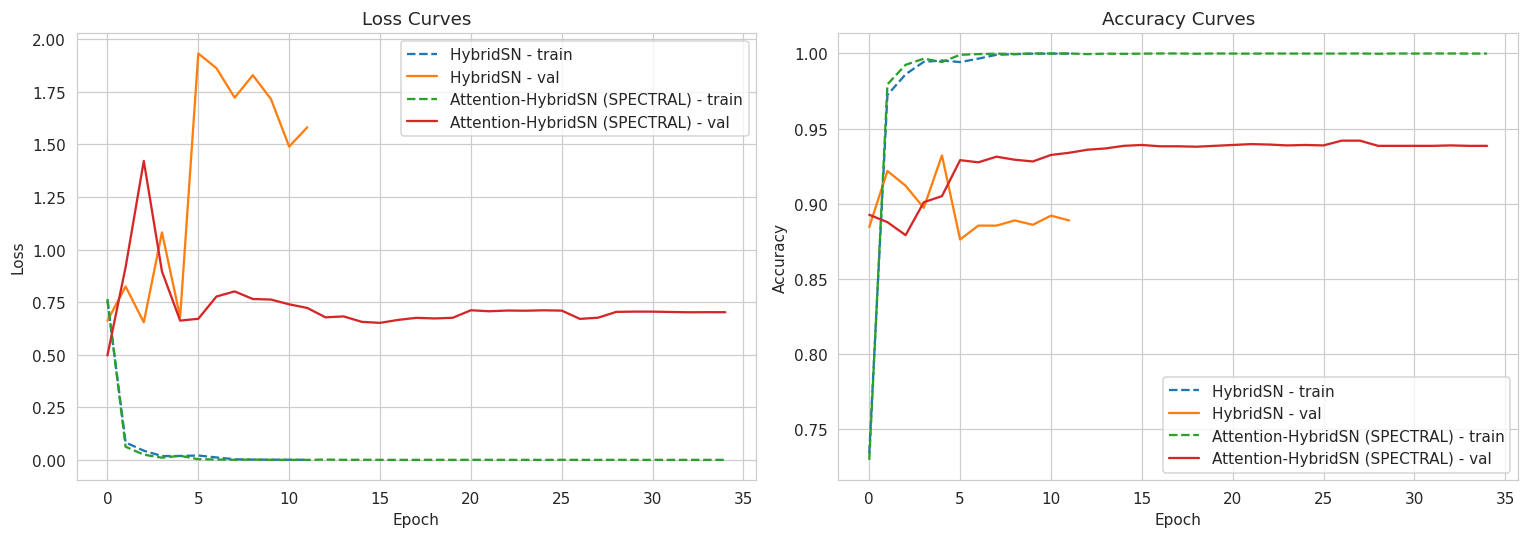

In [ ]:
#Plot training curves (loss + accuracy) — baseline vs. each attention variant
def plot_training_curves(history_a, history_b, label_a="HybridSN", label_b="Attention-HybridSN", save_path=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history_a["train_loss"], label=f"{label_a} - train", linestyle="--")
    axes[0].plot(history_a["val_loss"], label=f"{label_a} - val")
    axes[0].plot(history_b["train_loss"], label=f"{label_b} - train", linestyle="--")
    axes[0].plot(history_b["val_loss"], label=f"{label_b} - val")
    axes[0].set_title("Loss Curves")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

    axes[1].plot(history_a["train_acc"], label=f"{label_a} - train", linestyle="--")
    axes[1].plot(history_a["val_acc"], label=f"{label_a} - val")
    axes[1].plot(history_b["train_acc"], label=f"{label_b} - train", linestyle="--")
    axes[1].plot(history_b["val_acc"], label=f"{label_b} - val")
    axes[1].set_title("Accuracy Curves")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

for att_type in ATTENTION_TYPES:
    plot_training_curves(
        history_baseline, results[att_type]["history"],
        label_a="HybridSN", label_b=f"Attention-HybridSN ({att_type.upper()})",
        save_path=f"{FIGURE_DIR}/training_curves_{att_type}_{DATASET_NAME.replace(' ', '_')}.png"
    )


## Section 7 — Evaluation

Standard hyperspectral-classification metrics: **Overall Accuracy (OA)**, **Average Accuracy (AA)**,
**Cohen's Kappa**, per-class **Precision / Recall / F1**, per-class accuracy, confusion matrix, and a
full `sklearn` classification report — computed on the held-out **test set**.


In [ ]:
#Inference helper — collects predictions + ground truth over a loader
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    start = time.time()
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        logits = model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.append(preds)
        all_labels.append(yb.numpy())
    inference_time = time.time() - start
    return np.concatenate(all_preds), np.concatenate(all_labels), inference_time


In [ ]:
# Full metric suite
def evaluate_model(model, loader, class_names, model_name="Model"):
    preds, targets, inference_time = get_predictions(model, loader)

    all_labels = list(range(NUM_CLASSES))
    target_names_fixed = class_names[1:NUM_CLASSES + 1]

    oa = accuracy_score(targets, preds)
    kappa = cohen_kappa_score(targets, preds)
    cm = confusion_matrix(targets, preds, labels=all_labels)
    support_per_class = cm.sum(axis=1)
    per_class_acc = cm.diagonal() / support_per_class.clip(min=1)

    present_mask = support_per_class > 0
    aa = per_class_acc[present_mask].mean() if present_mask.any() else float("nan")

    precision, recall, f1, support = precision_recall_fscore_support(
        targets, preds, labels=all_labels, average=None, zero_division=0
    )
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        targets, preds, labels=all_labels, average="macro", zero_division=0
    )

    report = classification_report(
        targets, preds, labels=all_labels, target_names=target_names_fixed, zero_division=0
    )

    missing_classes = [target_names_fixed[i] for i in range(NUM_CLASSES) if support_per_class[i] == 0]
    if missing_classes:
        print(f"[{model_name}] WARNING: these classes have zero samples in this split "
              f"(excluded from AA, reported as 0 in the table): {missing_classes}")

    results = {
        "model_name": model_name,
        "OA": oa, "AA": aa, "Kappa": kappa,
        "Precision": macro_precision, "Recall": macro_recall, "F1": macro_f1,
        "per_class_accuracy": per_class_acc,
        "per_class_precision": precision, "per_class_recall": recall, "per_class_f1": f1,
        "confusion_matrix": cm,
        "classification_report": report,
        "inference_time": inference_time,
        "predictions": preds,
        "targets": targets,
    }

    print(f"===== {model_name} — Test Set Evaluation =====")
    print(f"Overall Accuracy (OA) : {oa*100:.2f}%")
    print(f"Average Accuracy (AA) : {aa*100:.2f}%  (averaged over {present_mask.sum()}/{NUM_CLASSES} classes present in this split)")
    print(f"Kappa Coefficient     : {kappa:.4f}")
    print(f"Macro Precision       : {macro_precision:.4f}")
    print(f"Macro Recall          : {macro_recall:.4f}")
    print(f"Macro F1-score        : {macro_f1:.4f}")
    print(f"Inference time (test set, {len(targets)} samples): {inference_time:.3f}s")
    print("\nClassification Report:\n", report)

    return results

class_names_used = meta["class_names"]
results_baseline = evaluate_model(baseline_model, test_loader, class_names_used, "HybridSN")


[HybridSN] WARNING: these classes have zero samples in this split (excluded from AA, reported as 0 in the table): ['Brocoli_green_weeds_1', 'Fallow_rough_plow', 'Lettuce_romaine_4wk', 'Lettuce_romaine_5wk', 'Vinyard_vertical_trellis']
===== HybridSN — Test Set Evaluation =====
Overall Accuracy (OA) : 95.84%
Average Accuracy (AA) : 97.90%  (averaged over 11/16 classes present in this split)
Kappa Coefficient     : 0.9500
Macro Precision       : 0.6377
Macro Recall          : 0.6730
Macro F1-score        : 0.6435
Inference time (test set, 5163 samples): 0.324s

Classification Report:
                            precision    recall  f1-score   support

    Brocoli_green_weeds_1       0.00      0.00      0.00         0
    Brocoli_green_weeds_2       1.00      1.00      1.00       528
                   Fallow       1.00      0.98      0.99       494
        Fallow_rough_plow       0.00      0.00      0.00         0
            Fallow_smooth       0.96      1.00      0.98       132
       

In [ ]:
#Evaluate every attention-enhanced model on the held-out test set
eval_results = {}   # att_type -> evaluate_model() output dict
for att_type in ATTENTION_TYPES:
    eval_results[att_type] = evaluate_model(
        trained_models[att_type], test_loader, class_names_used,
        f"Attention-HybridSN ({att_type.upper()})"
    )


[Attention-HybridSN (SE)] WARNING: these classes have zero samples in this split (excluded from AA, reported as 0 in the table): ['Brocoli_green_weeds_1', 'Fallow_rough_plow', 'Lettuce_romaine_4wk', 'Lettuce_romaine_5wk', 'Vinyard_vertical_trellis']
===== Attention-HybridSN (SE) — Test Set Evaluation =====
Overall Accuracy (OA) : 96.13%
Average Accuracy (AA) : 97.38%  (averaged over 11/16 classes present in this split)
Kappa Coefficient     : 0.9534
Macro Precision       : 0.6352
Macro Recall          : 0.6695
Macro F1-score        : 0.6419
Inference time (test set, 5163 samples): 0.332s

Classification Report:
                            precision    recall  f1-score   support

    Brocoli_green_weeds_1       0.00      0.00      0.00         0
    Brocoli_green_weeds_2       1.00      0.99      1.00       528
                   Fallow       1.00      1.00      1.00       494
        Fallow_rough_plow       0.00      0.00      0.00         0
            Fallow_smooth       1.00      1.

In [ ]:

def get_model_key(model_choice, attention_choice):
    if model_choice == "HybridSN":
        return "HybridSN"
    return f"Attention-HybridSN ({attention_choice.upper()})"

if "TRAINED_RUNS" not in globals():
    TRAINED_RUNS = {}

TRAINED_RUNS["HybridSN"] = {
    "model": baseline_model, "history": history_baseline,
    "train_time": time_baseline, "checkpoint": ckpt_baseline,
    "results": results_baseline,
}

for att_type in ATTENTION_TYPES:
    TRAINED_RUNS[get_model_key("Attention-Enhanced HybridSN", att_type)] = {
        "model": trained_models[att_type],
        "history": results[att_type]["history"],
        "train_time": results[att_type]["train_time"],
        "checkpoint": results[att_type]["ckpt_path"],
        "results": eval_results[att_type],
    }

print("TRAINED_RUNS keys:", list(TRAINED_RUNS.keys()))


TRAINED_RUNS keys: ['HybridSN', 'Attention-HybridSN (SE)', 'Attention-HybridSN (CBAM)', 'Attention-HybridSN (SPECTRAL)']


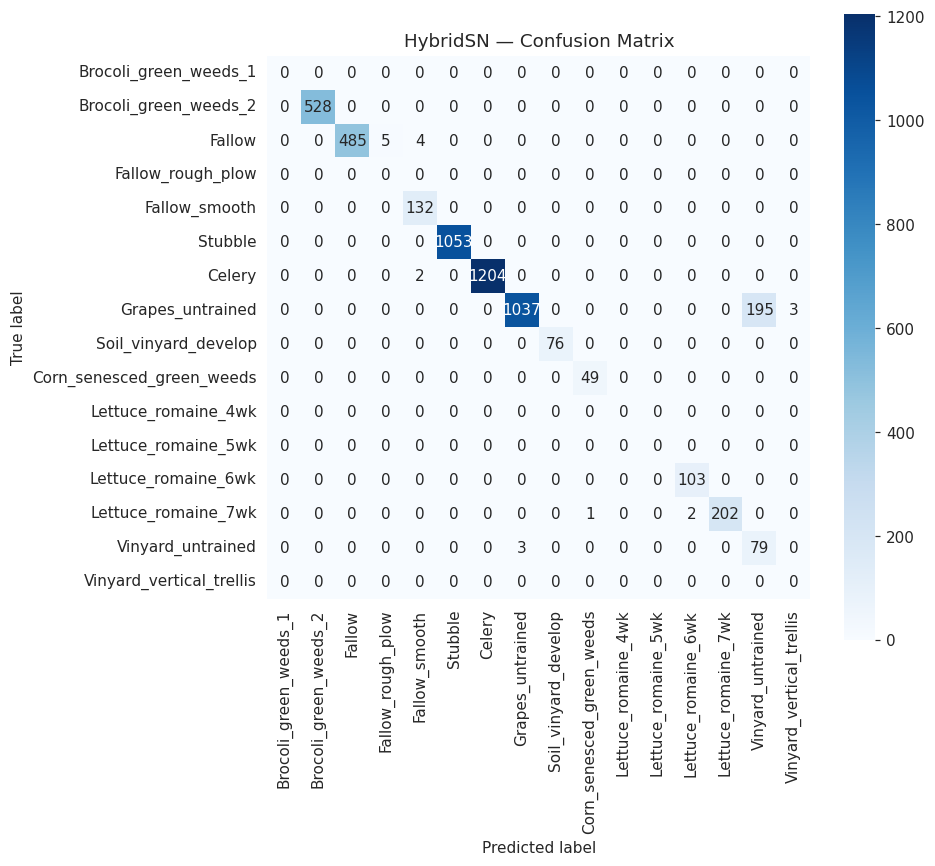

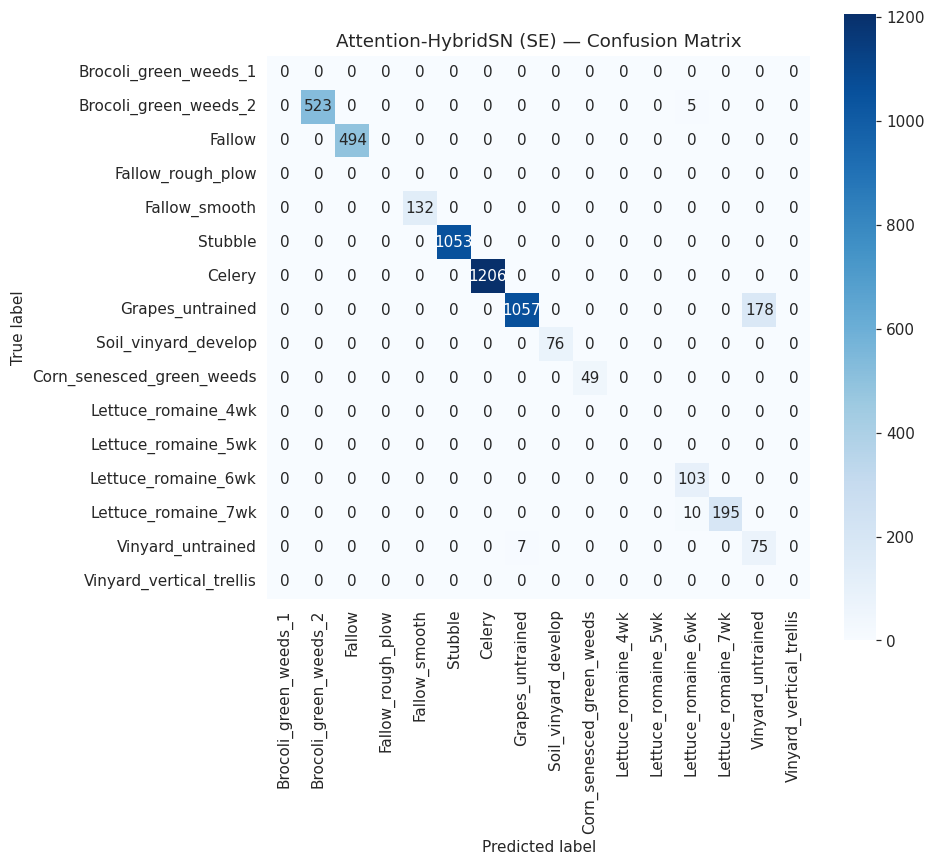

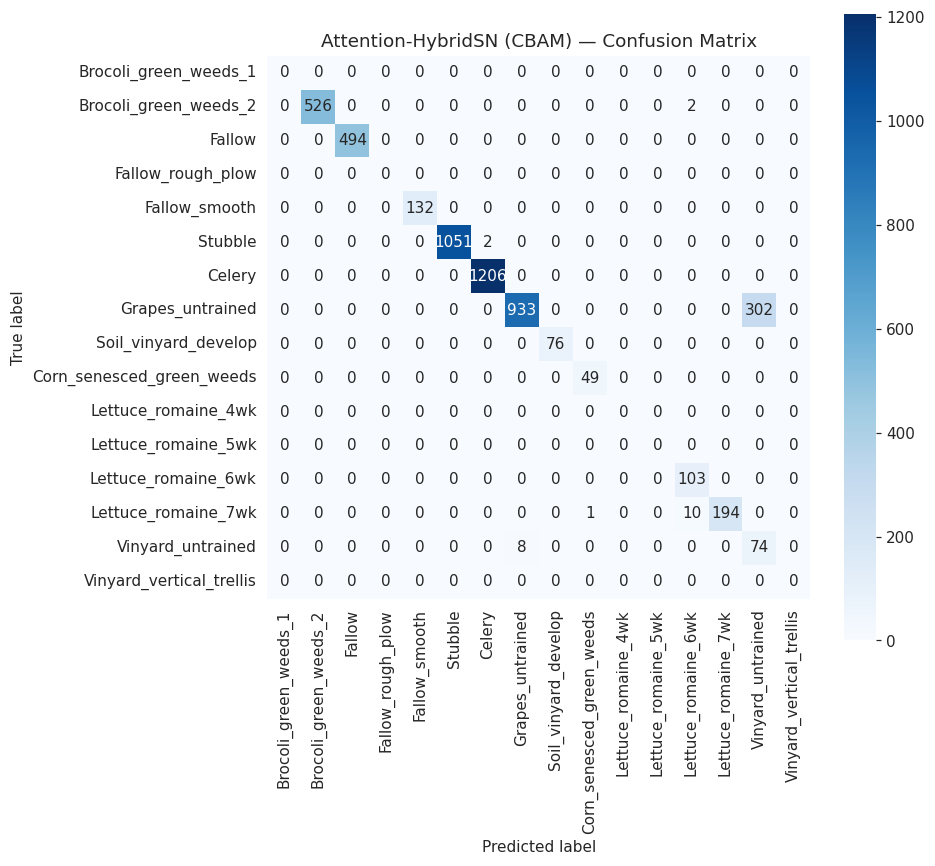

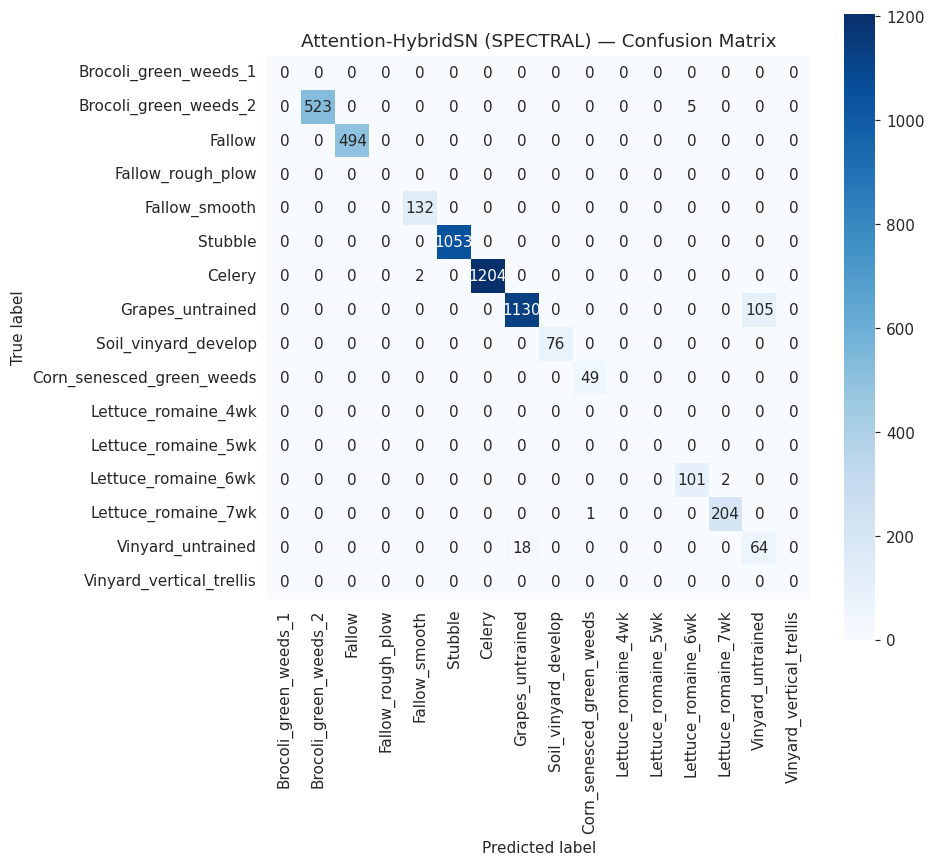

In [ ]:
#Confusion matrix plots — baseline + every attention variant
def plot_confusion_matrix(cm, class_names, title="Confusion Matrix", save_path=None):
    labels = class_names[1:cm.shape[0] + 1] if len(class_names) > cm.shape[0] else class_names
    plt.figure(figsize=(max(8, cm.shape[0] * 0.55), max(6, cm.shape[0] * 0.5)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels,
                cbar=True, square=True)
    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

plot_confusion_matrix(
    results_baseline["confusion_matrix"], class_names_used, title="HybridSN — Confusion Matrix",
    save_path=f"{FIGURE_DIR}/confusion_matrix_HybridSN_{DATASET_NAME.replace(' ', '_')}.png"
)

for att_type in ATTENTION_TYPES:
    plot_confusion_matrix(
        eval_results[att_type]["confusion_matrix"], class_names_used,
        title=f"Attention-HybridSN ({att_type.upper()}) — Confusion Matrix",
        save_path=f"{FIGURE_DIR}/confusion_matrix_{att_type}_{DATASET_NAME.replace(' ', '_')}.png"
    )


In [ ]:
#Per-class accuracy comparison table — HybridSN vs. SE vs. CBAM vs. Spectral
per_class_df = pd.DataFrame({
    "Class": class_names_used[1:len(results_baseline['per_class_accuracy']) + 1],
    "HybridSN Acc (%)": results_baseline["per_class_accuracy"] * 100,
})
for att_type in ATTENTION_TYPES:
    per_class_df[f"{att_type.upper()} Acc (%)"] = eval_results[att_type]["per_class_accuracy"] * 100
    per_class_df[f"{att_type.upper()} Improvement (%)"] = (
        per_class_df[f"{att_type.upper()} Acc (%)"] - per_class_df["HybridSN Acc (%)"]
    )
per_class_df = per_class_df.round(2)
per_class_df


,Class,HybridSN Acc (%),SE Acc (%),SE Improvement (%),CBAM Acc (%),CBAM Improvement (%),SPECTRAL Acc (%),SPECTRAL Improvement (%)
0,Brocoli_green_weeds_1,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,Brocoli_green_weeds_2,100.00,99.05,-0.95,99.62,-0.38,99.05,-0.95
2,Fallow,98.18,100.00,1.82,100.00,1.82,100.00,1.82
3,Fallow_rough_plow,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,Fallow_smooth,100.00,100.00,0.00,100.00,0.00,100.00,0.00
5,Stubble,100.00,100.00,0.00,99.81,-0.19,100.00,0.00
6,Celery,99.83,100.00,0.17,100.00,0.17,99.83,0.00
7,Grapes_untrained,83.97,85.59,1.62,75.55,-8.42,91.50,7.53
8,Soil_vinyard_develop,100.00,100.00,0.00,100.00,0.00,100.00,0.00
9,Corn_senesced_green_weeds,100.00,100.00,0.00,100.00,0.00,100.00,0.00


## Section 8 — Result Comparison: HybridSN vs. Attention-Enhanced HybridSN



In [ ]:
#Parameter counts + timing summary table — all 4 models
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

rows = [{
    "Model": "HybridSN",
    "OA (%)": results_baseline["OA"] * 100,
    "AA (%)": results_baseline["AA"] * 100,
    "Kappa": results_baseline["Kappa"],
    "Precision": results_baseline["Precision"],
    "Recall": results_baseline["Recall"],
    "F1-score": results_baseline["F1"],
    "Training Time (s)": time_baseline,
    "Inference Time (s)": results_baseline["inference_time"],
    "Parameters": count_params(baseline_model),
}]

for att_type in ATTENTION_TYPES:
    r = eval_results[att_type]
    rows.append({
        "Model": f"Attention-HybridSN ({att_type.upper()})",
        "OA (%)": r["OA"] * 100,
        "AA (%)": r["AA"] * 100,
        "Kappa": r["Kappa"],
        "Precision": r["Precision"],
        "Recall": r["Recall"],
        "F1-score": r["F1"],
        "Training Time (s)": results[att_type]["train_time"],
        "Inference Time (s)": r["inference_time"],
        "Parameters": count_params(trained_models[att_type]),
    })

comparison_df = pd.DataFrame(rows).round(4)
comparison_df


,Model,OA (%),AA (%),Kappa,Precision,Recall,F1-score,Training Time (s),Inference Time (s),Parameters
0,HybridSN,95.8358,97.8962,0.9500,0.6377,0.6730,0.6435,26.9368,0.3243,534656
1,Attention-HybridSN (SE),96.1263,97.3841,0.9534,0.6352,0.6695,0.6419,42.3506,0.3323,617600
2,Attention-HybridSN (CBAM),93.7052,96.3505,0.9248,0.6289,0.6624,0.6303,25.3063,0.2839,617698
3,Attention-HybridSN (SPECTRAL),97.4240,96.9095,0.9689,0.6420,0.6663,0.6496,204.8119,0.5528,538634


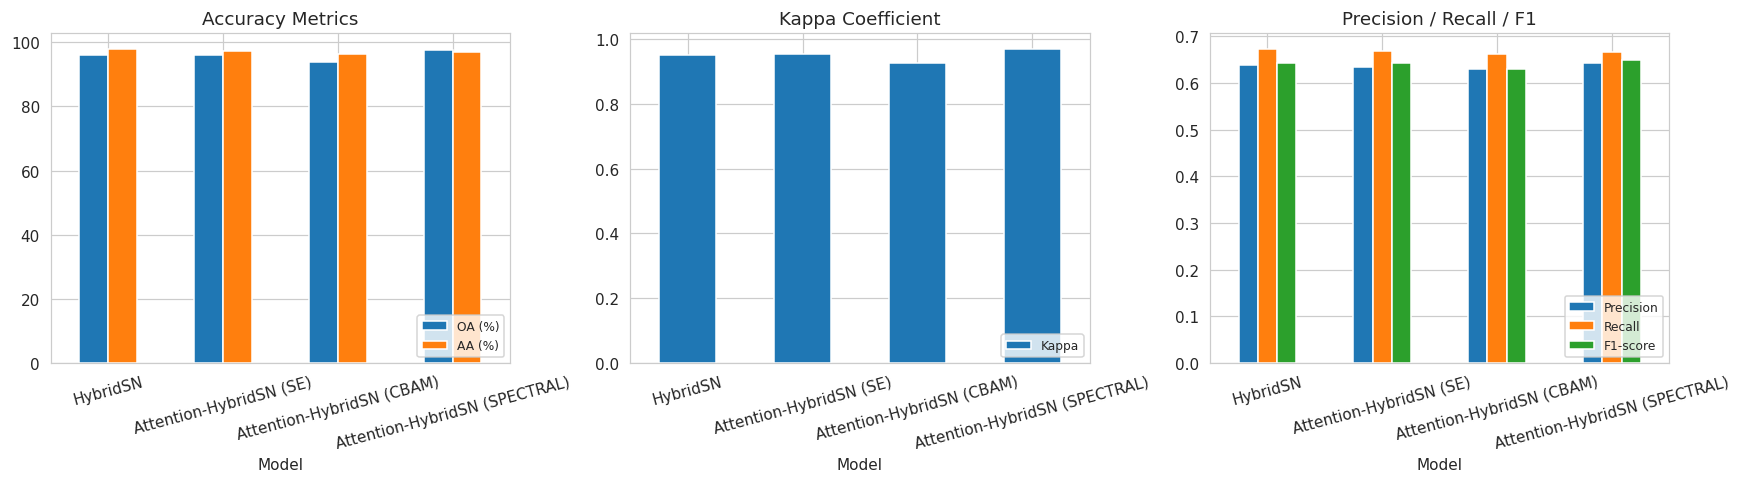

In [ ]:
#Bar chart comparison across headline metrics
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metrics_to_plot = [("OA (%)", "AA (%)"), ("Kappa",), ("Precision", "Recall", "F1-score")]
titles = ["Accuracy Metrics", "Kappa Coefficient", "Precision / Recall / F1"]

for ax, metric_group, title in zip(axes, metrics_to_plot, titles):
    sub = comparison_df.set_index("Model")[list(metric_group)]
    sub.plot(kind="bar", ax=ax, rot=15)
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/metric_comparison_bars_{DATASET_NAME.replace(' ', '_')}.png", bbox_inches="tight")
plt.show()


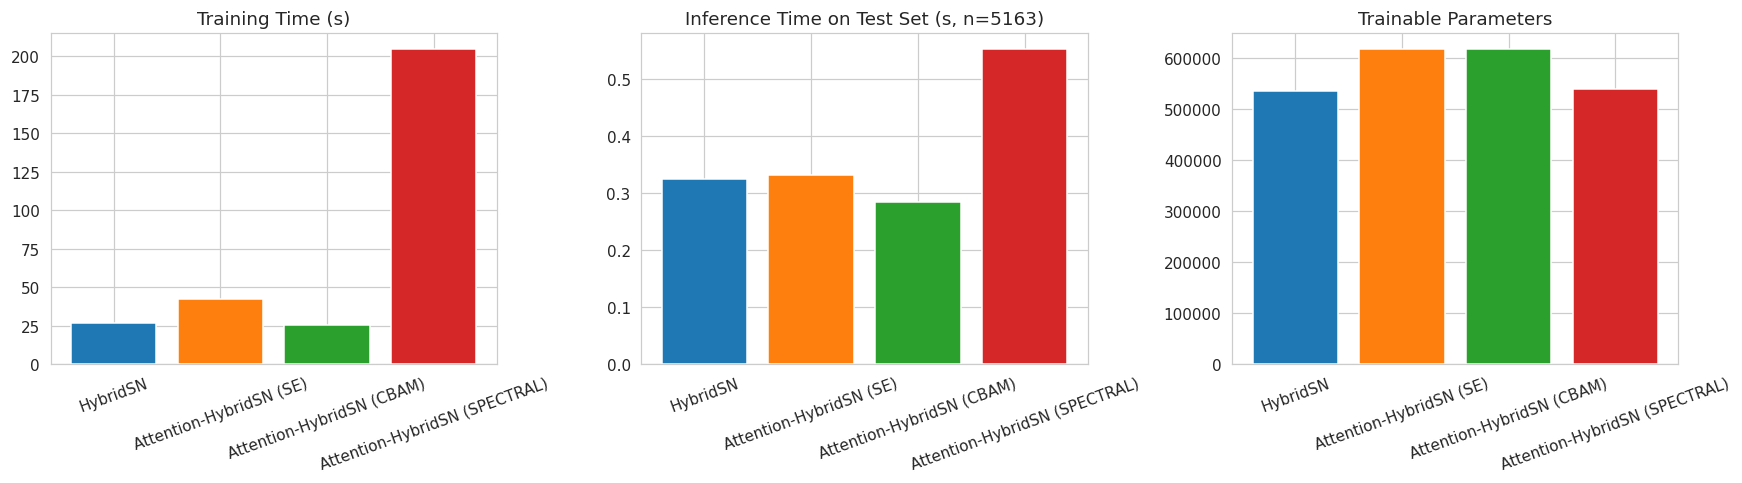

OA improvement over baseline HybridSN:
  SE        : +0.29 percentage points
  CBAM      : -2.13 percentage points
  SPECTRAL  : +1.59 percentage points


In [ ]:
#Efficiency comparison (training time, inference time, parameter count) — all 4 models
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
bar_colors = plt.cm.tab10.colors[:len(comparison_df)]

axes[0].bar(comparison_df["Model"], comparison_df["Training Time (s)"], color=bar_colors)
axes[0].set_title("Training Time (s)"); axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(comparison_df["Model"], comparison_df["Inference Time (s)"], color=bar_colors)
axes[1].set_title(f"Inference Time on Test Set (s, n={len(results_baseline['targets'])})")
axes[1].tick_params(axis="x", rotation=20)

axes[2].bar(comparison_df["Model"], comparison_df["Parameters"], color=bar_colors)
axes[2].set_title("Trainable Parameters"); axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/efficiency_comparison_{DATASET_NAME.replace(' ', '_')}.png", bbox_inches="tight")
plt.show()

print("OA improvement over baseline HybridSN:")
for att_type in ATTENTION_TYPES:
    improvement_oa = (eval_results[att_type]['OA'] - results_baseline['OA']) * 100
    print(f"  {att_type.upper():10s}: {improvement_oa:+.2f} percentage points")


## Section 9 — Visualization


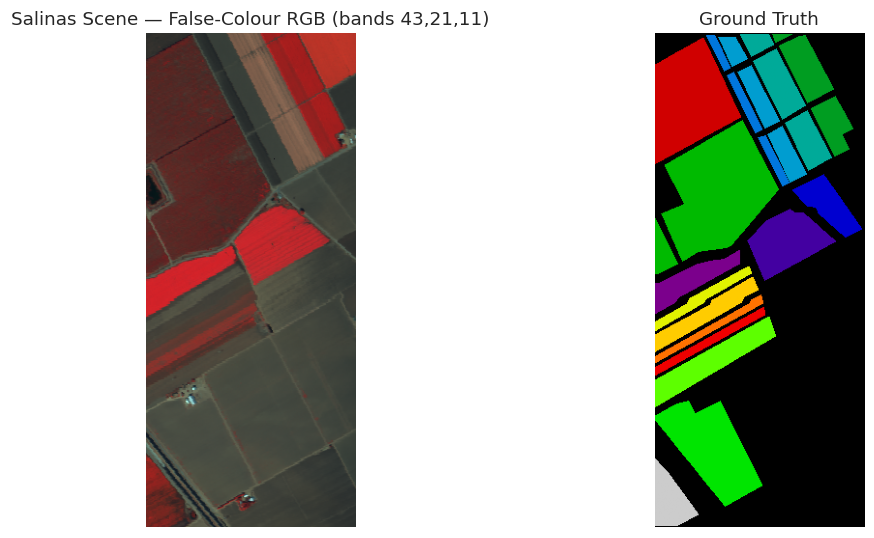

In [ ]:
#RGB false-colour composite + ground-truth map
def show_rgb_and_gt(cube, gt, meta, save_path=None):
    r, g, b = meta["rgb_bands"]
    r, g, b = min(r, cube.shape[-1]-1), min(g, cube.shape[-1]-1), min(b, cube.shape[-1]-1)
    rgb = cube[:, :, [r, g, b]]
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(rgb)
    axes[0].set_title(f"{meta['dataset_name']} — False-Colour RGB (bands {r},{g},{b})")
    axes[0].axis("off")

    cmap = plt.get_cmap("nipy_spectral", meta["num_classes"] + 1)
    axes[1].imshow(gt, cmap=cmap, vmin=0, vmax=meta["num_classes"])
    axes[1].set_title("Ground Truth")
    axes[1].axis("off")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()
    return rgb

rgb_image = show_rgb_and_gt(
    cube, gt, meta, save_path=f"{FIGURE_DIR}/rgb_and_gt_{DATASET_NAME.replace(' ', '_')}.png"
)


In [ ]:
#Full-scene prediction map generator
@torch.no_grad()
def predict_full_scene(model, cube_pca, gt, patch_size, batch_size=256):
    model.eval()
    h, w = gt.shape
    margin = patch_size // 2
    padded = pad_with_zeros(cube_pca, margin)

    pred_map = np.full((h, w), -1, dtype=np.int64)
    coords = [(i, j) for i in range(h) for j in range(w)]

    for start in range(0, len(coords), batch_size):
        batch_coords = coords[start:start + batch_size]
        batch_patches = np.stack([
            padded[i:i + patch_size, j:j + patch_size, :] for (i, j) in batch_coords
        ]).astype(np.float32)
        tensor = torch.from_numpy(batch_patches.transpose(0, 3, 1, 2)).unsqueeze(1).to(DEVICE)
        preds = model(tensor).argmax(dim=1).cpu().numpy()
        for (i, j), p in zip(batch_coords, preds):
            pred_map[i, j] = p

    return pred_map

print("Generating full-scene prediction maps (this may take a minute)...")
pred_map_baseline = predict_full_scene(baseline_model, cube_pca, gt, PATCH_SIZE)
pred_maps_attention = {
    att_type: predict_full_scene(trained_models[att_type], cube_pca, gt, PATCH_SIZE)
    for att_type in ATTENTION_TYPES
}
print("Done.")


Generating full-scene prediction maps (this may take a minute)...
Done.


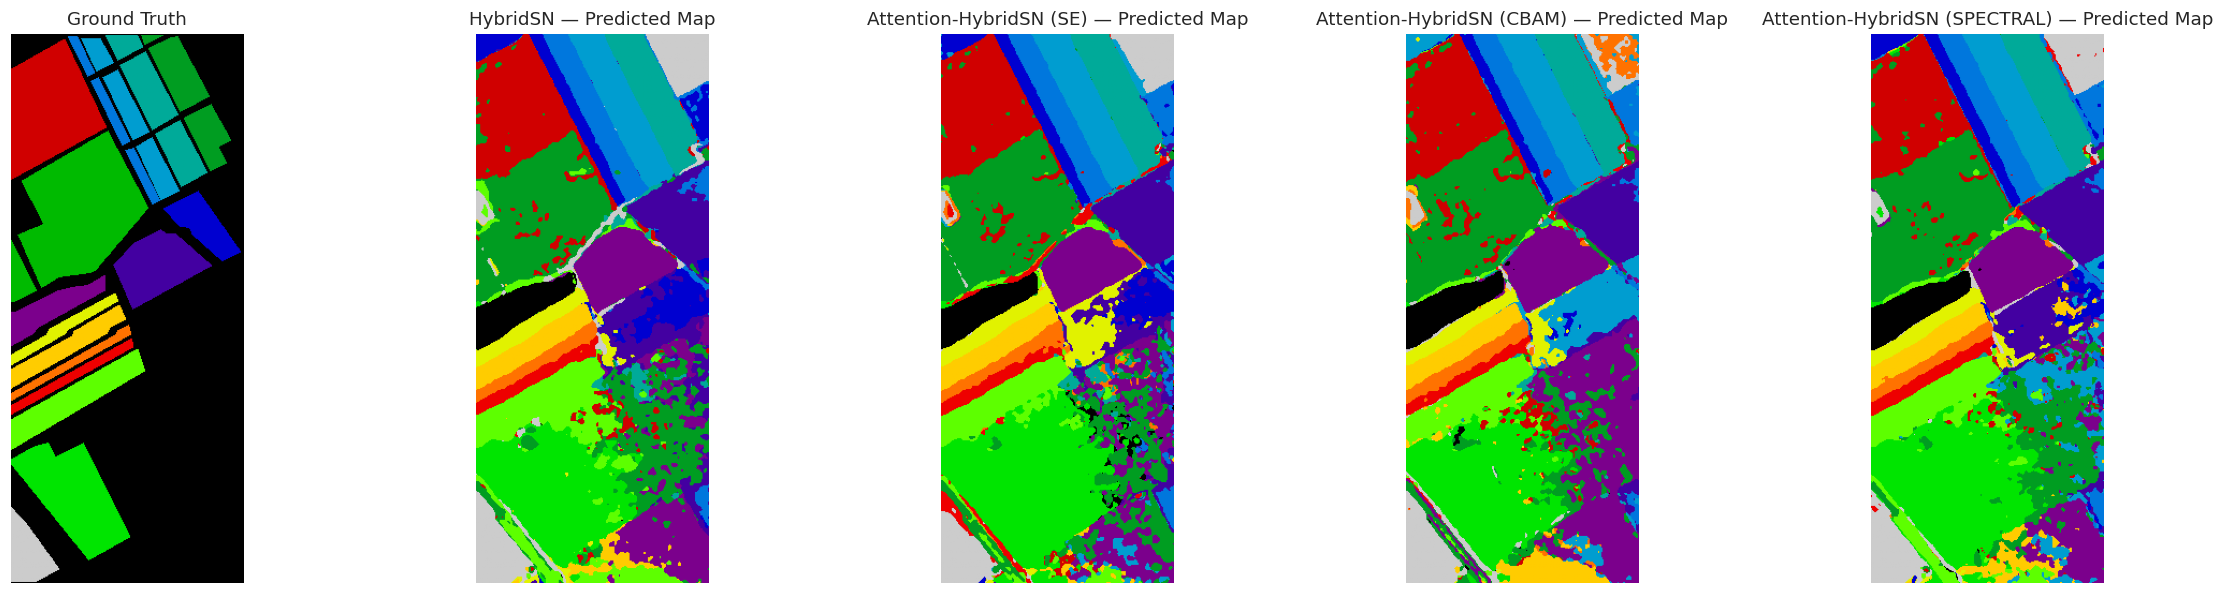

In [ ]:
#Plot ground truth vs. predicted maps for every model
def plot_classification_maps(gt, pred_baseline, pred_attention_dict, num_classes, save_path=None):
    cmap = plt.get_cmap("nipy_spectral", num_classes + 1)
    n_models = 1 + len(pred_attention_dict)  # baseline + each attention variant
    fig, axes = plt.subplots(1, n_models + 1, figsize=(4.5 * (n_models + 1), 5.5))

    axes[0].imshow(gt, cmap=cmap, vmin=0, vmax=num_classes)
    axes[0].set_title("Ground Truth"); axes[0].axis("off")

    masked_baseline = np.ma.masked_where(pred_baseline < 0, pred_baseline)
    axes[1].imshow(masked_baseline, cmap=cmap, vmin=0, vmax=num_classes - 1)
    axes[1].set_title("HybridSN — Predicted Map"); axes[1].axis("off")

    for i, (att_type, pred_map) in enumerate(pred_attention_dict.items(), start=2):
        masked = np.ma.masked_where(pred_map < 0, pred_map)
        axes[i].imshow(masked, cmap=cmap, vmin=0, vmax=num_classes - 1)
        axes[i].set_title(f"Attention-HybridSN ({att_type.upper()}) — Predicted Map"); axes[i].axis("off")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

plot_classification_maps(
    gt, pred_map_baseline, pred_maps_attention, NUM_CLASSES,
    save_path=f"{FIGURE_DIR}/classification_maps_{DATASET_NAME.replace(' ', '_')}.png"
)


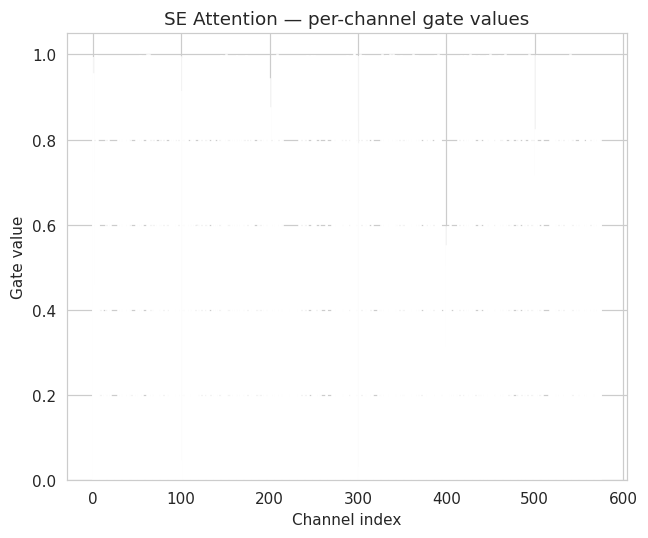

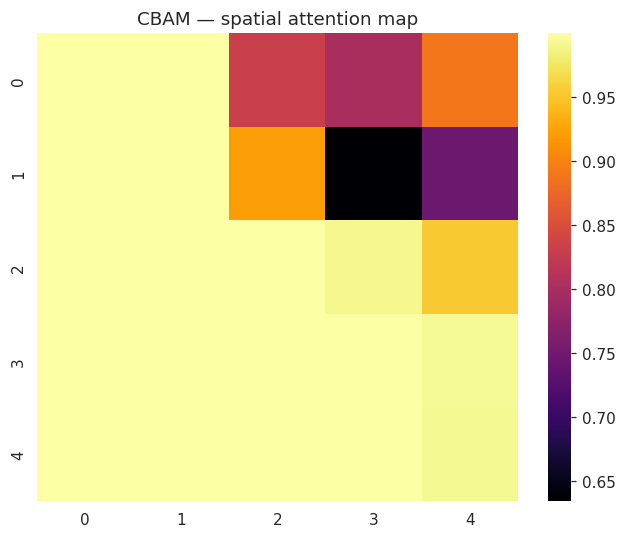

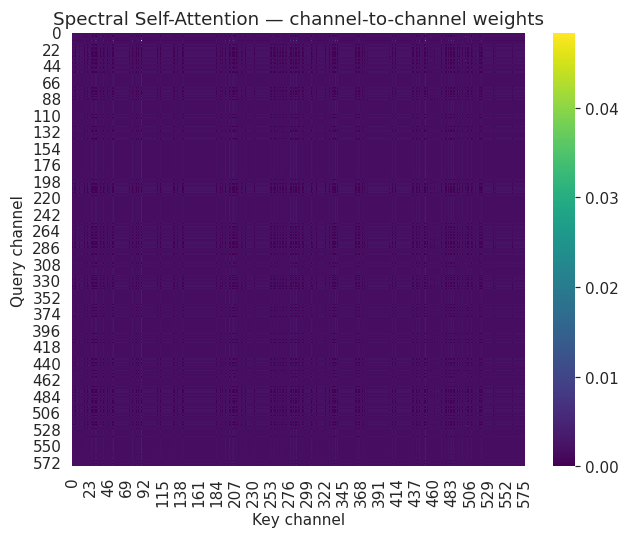

In [ ]:
# Attention heatmap visualization — one per attention-enhanced model
@torch.no_grad()
def visualize_attention_heatmap(model, sample_patch, attention_type, save_path=None):

    model.eval()
    x = sample_patch.unsqueeze(0).to(DEVICE)
    _ = model(x)
    attn = model.get_last_attention_map()

    if attn is None:
        print("No attention map available (attention_type='none').")
        return

    plt.figure(figsize=(6, 5))
    if attention_type == "se":
        values = attn.squeeze().cpu().numpy()
        plt.bar(range(len(values)), values)
        plt.title("SE Attention — per-channel gate values")
        plt.xlabel("Channel index"); plt.ylabel("Gate value")
    elif attention_type == "cbam":
        spatial_map = attn.squeeze().cpu().numpy()
        sns.heatmap(spatial_map, cmap="inferno", cbar=True)
        plt.title("CBAM — spatial attention map")
    elif attention_type == "spectral":
        attn_matrix = attn.squeeze().cpu().numpy()
        sns.heatmap(attn_matrix, cmap="viridis", cbar=True)
        plt.title("Spectral Self-Attention — channel-to-channel weights")
        plt.xlabel("Key channel"); plt.ylabel("Query channel")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

sample_patch, _ = test_dataset[0]
for att_type in ATTENTION_TYPES:
    visualize_attention_heatmap(
        trained_models[att_type], sample_patch, att_type,
        save_path=f"{FIGURE_DIR}/attention_heatmap_{att_type}_{DATASET_NAME.replace(' ', '_')}.png"
    )


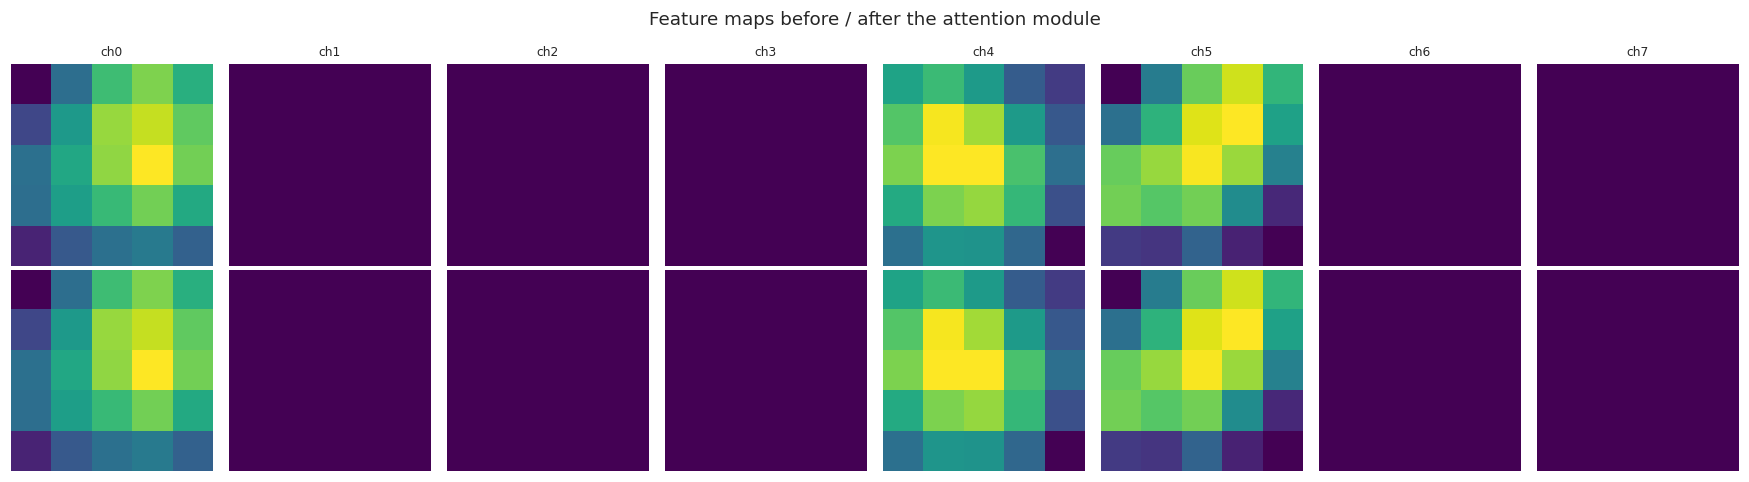

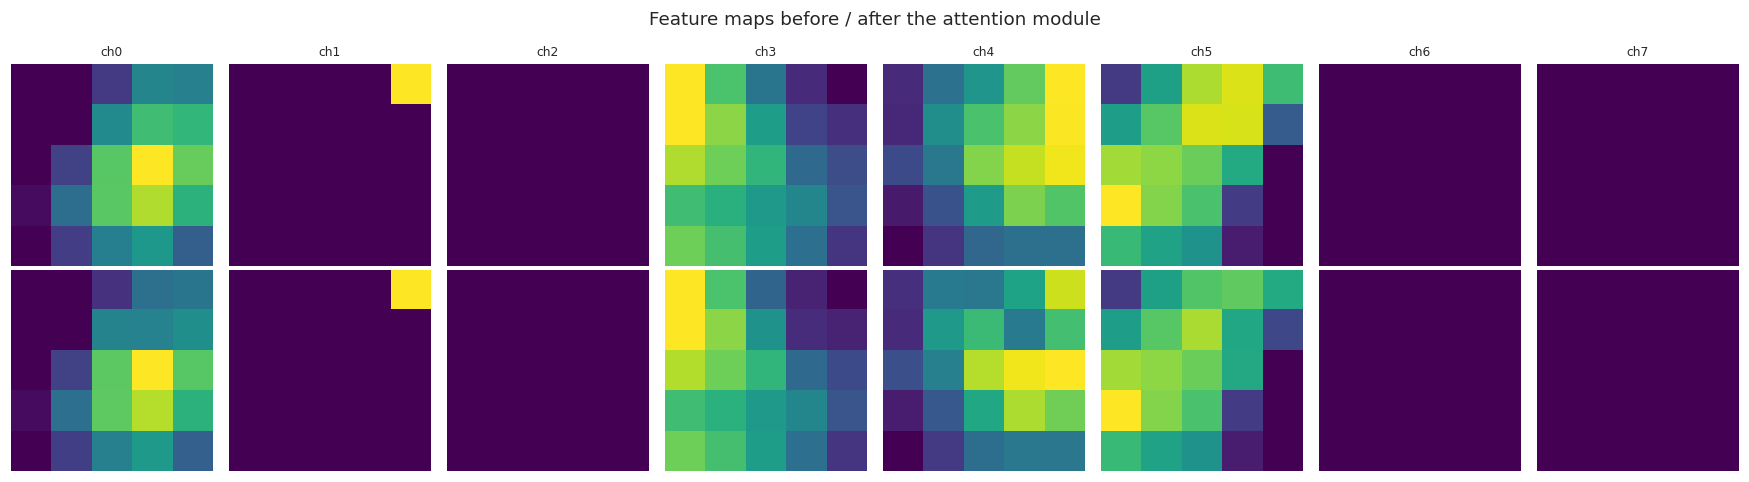

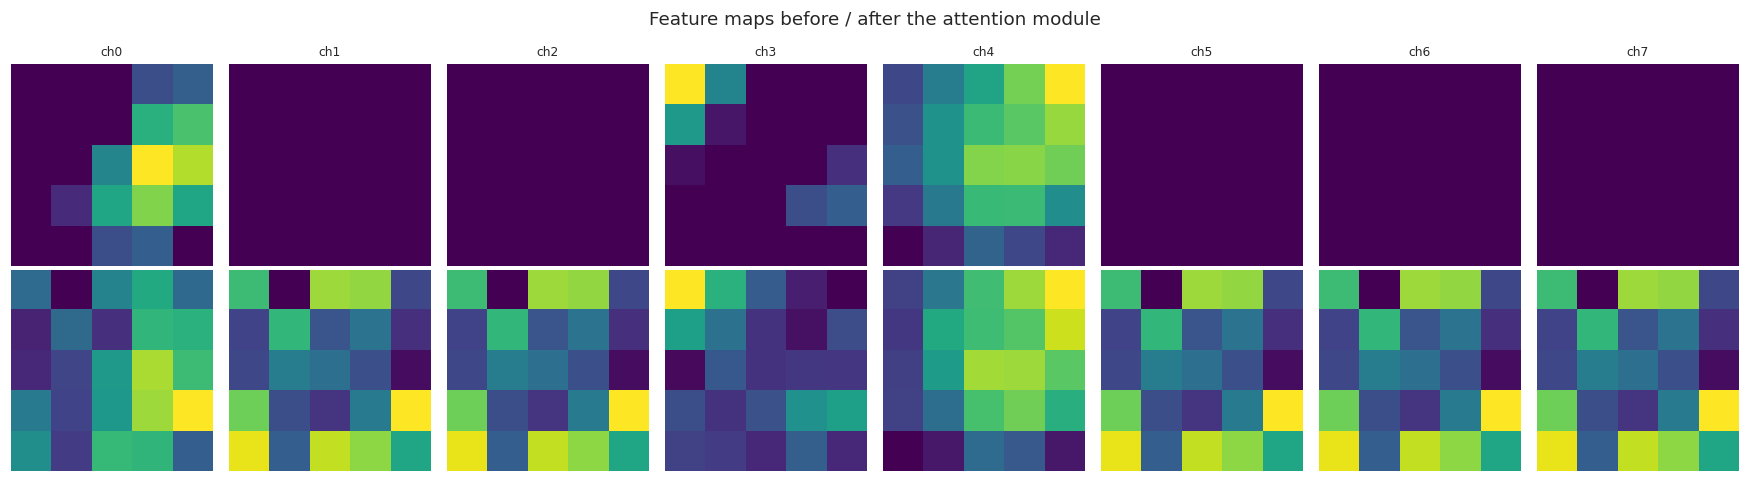

In [ ]:
# Intermediate feature-map visualization (after the 3D->2D reshape, pre- and post-attention)
@torch.no_grad()
def visualize_feature_maps(model, sample_patch, n_maps=8, save_path=None):
    model.eval()
    x = sample_patch.unsqueeze(0).to(DEVICE)

    feat3d = model._forward_3d(x)
    b, c, d, h, w = feat3d.shape
    reshaped = feat3d.reshape(b, c * d, h, w)
    attended = model.attention(reshaped)

    fig, axes = plt.subplots(2, n_maps, figsize=(2 * n_maps, 4.5))
    for i in range(n_maps):
        axes[0, i].imshow(reshaped[0, i].cpu().numpy(), cmap="viridis")
        axes[0, i].axis("off")
        axes[0, i].set_title(f"ch{i}", fontsize=8)
        axes[1, i].imshow(attended[0, i].cpu().numpy(), cmap="viridis")
        axes[1, i].axis("off")

    axes[0, 0].set_ylabel("Pre-attention", fontsize=10)
    axes[1, 0].set_ylabel("Post-attention", fontsize=10)
    fig.suptitle("Feature maps before / after the attention module")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

for att_type in ATTENTION_TYPES:
    fig_suptitle = f"Feature maps before / after the {att_type.upper()} attention module"
    visualize_feature_maps(
        trained_models[att_type], sample_patch,
        save_path=f"{FIGURE_DIR}/feature_maps_{att_type}_{DATASET_NAME.replace(' ', '_')}.png"
    )


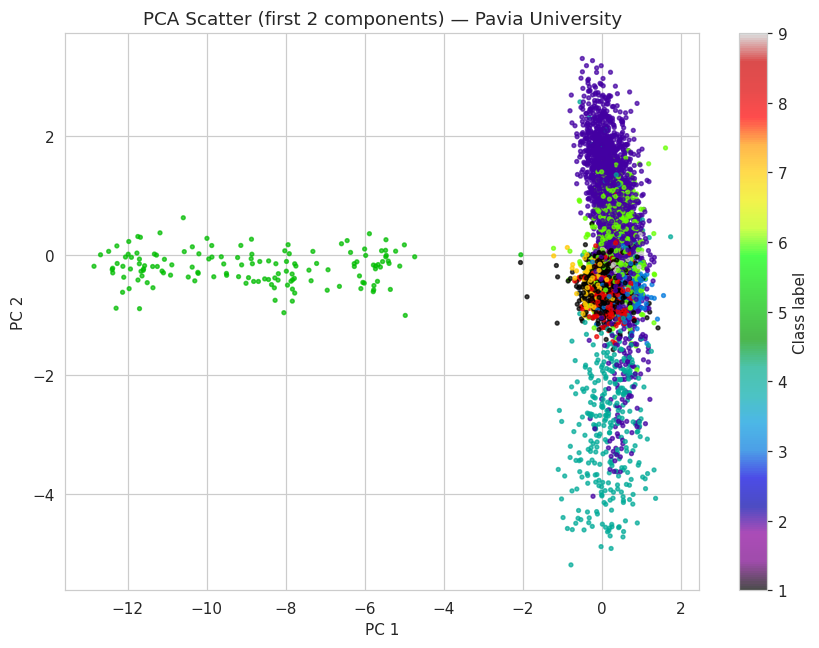

In [ ]:
#PCA visualization — 2D scatter of the first two principal components, coloured by class
def plot_pca_scatter(cube_norm, gt, class_names, n_samples=5000, save_path=None):
    h, w, b = cube_norm.shape
    flat = cube_norm.reshape(-1, b)
    flat_gt = gt.reshape(-1)

    mask = flat_gt > 0
    flat, flat_gt = flat[mask], flat_gt[mask]

    if len(flat) > n_samples:
        idx = np.random.choice(len(flat), n_samples, replace=False)
        flat, flat_gt = flat[idx], flat_gt[idx]

    pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(flat)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(pca_2d[:, 0], pca_2d[:, 1], c=flat_gt, cmap="nipy_spectral", s=6, alpha=0.7)
    plt.colorbar(scatter, label="Class label")
    plt.title(f"PCA Scatter (first 2 components) — {meta['dataset_name']}")
    plt.xlabel("PC 1"); plt.ylabel("PC 2")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

plot_pca_scatter(
    cube_pca, gt, meta["class_names"],
    save_path=f"{FIGURE_DIR}/pca_scatter_{DATASET_NAME.replace(' ', '_')}.png"
)

## Section 10 — Outputs



In [ ]:
# Save evaluation metrics as CSV
metrics_csv_path = f"{REPORT_DIR}/metrics_comparison_{DATASET_NAME.replace(' ', '_')}.csv"
comparison_df.to_csv(metrics_csv_path, index=False)
print(f"Saved metrics comparison table -> {metrics_csv_path}")

per_class_csv_path = f"{REPORT_DIR}/per_class_accuracy_{DATASET_NAME.replace(' ', '_')}.csv"
per_class_df.to_csv(per_class_csv_path, index=False)
print(f"Saved per-class accuracy table -> {per_class_csv_path}")


Saved metrics comparison table -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/metrics_comparison_Pavia_University.csv
Saved per-class accuracy table -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/per_class_accuracy_Pavia_University.csv


In [ ]:
# Save classification reports as text files — baseline + every attention variant
report_targets = [("HybridSN", results_baseline)]
for att_type in ATTENTION_TYPES:
    report_targets.append((f"AttentionHybridSN_{att_type}", eval_results[att_type]))

for name, results_r in report_targets:
    report_path = f"{REPORT_DIR}/classification_report_{name}_{DATASET_NAME.replace(' ', '_')}.txt"
    with open(report_path, "w") as f:
        f.write(f"Classification Report — {name} — {DATASET_NAME}\n")
        f.write("=" * 60 + "\n")
        f.write(f"OA: {results_r['OA']*100:.2f}%  AA: {results_r['AA']*100:.2f}%  Kappa: {results_r['Kappa']:.4f}\n\n")
        f.write(results_r["classification_report"])
    print(f"Saved classification report -> {report_path}")


Saved classification report -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/classification_report_HybridSN_Pavia_University.txt
Saved classification report -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/classification_report_AttentionHybridSN_se_Pavia_University.txt
Saved classification report -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/classification_report_AttentionHybridSN_cbam_Pavia_University.txt
Saved classification report -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/classification_report_AttentionHybridSN_spectral_Pavia_University.txt


In [ ]:
# Save confusion matrices as .npy (raw data, for later re-plotting / statistical tests)
cm_targets = [("HybridSN", results_baseline)]
for att_type in ATTENTION_TYPES:
    cm_targets.append((f"AttentionHybridSN_{att_type}", eval_results[att_type]))

for name, results_r in cm_targets:
    cm_path = f"{REPORT_DIR}/confusion_matrix_{name}_{DATASET_NAME.replace(' ', '_')}.npy"
    np.save(cm_path, results_r["confusion_matrix"])
    print(f"Saved confusion matrix array -> {cm_path}")


Saved confusion matrix array -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/confusion_matrix_HybridSN_Pavia_University.npy
Saved confusion matrix array -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/confusion_matrix_AttentionHybridSN_se_Pavia_University.npy
Saved confusion matrix array -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/confusion_matrix_AttentionHybridSN_cbam_Pavia_University.npy
Saved confusion matrix array -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/confusion_matrix_AttentionHybridSN_spectral_Pavia_University.npy


In [ ]:
# Save experiment run summary (JSON) — useful for reproducibility appendix in the thesis
run_summary = {
    "timestamp": datetime.now().isoformat(),
    "dataset": DATASET_NAME,
    "patch_size": PATCH_SIZE,
    "pca_components": N_PCA_COMPONENTS if USE_PCA else None,
    "num_classes": NUM_CLASSES,
    "attention_types_trained": ATTENTION_TYPES,
    "train_config": TRAIN_CONFIG,
    "seed": SEED,
    "results": {
        "HybridSN": {k: (v if isinstance(v, (int, float, str)) else None)
                     for k, v in results_baseline.items() if k not in
                     ["confusion_matrix", "predictions", "targets", "per_class_accuracy",
                      "per_class_precision", "per_class_recall", "per_class_f1", "classification_report"]},
    },
    "checkpoints": {"HybridSN": ckpt_baseline},
}

for att_type in ATTENTION_TYPES:
    run_summary["results"][f"AttentionHybridSN_{att_type}"] = {
        k: (v if isinstance(v, (int, float, str)) else None)
        for k, v in eval_results[att_type].items() if k not in
        ["confusion_matrix", "predictions", "targets", "per_class_accuracy",
         "per_class_precision", "per_class_recall", "per_class_f1", "classification_report"]
    }
    run_summary["checkpoints"][f"AttentionHybridSN_{att_type}"] = results[att_type]["ckpt_path"]

summary_path = f"{REPORT_DIR}/run_summary_{DATASET_NAME.replace(' ', '_')}.json"
with open(summary_path, "w") as f:
    json.dump(run_summary, f, indent=2, default=str)
print(f"Saved run summary -> {summary_path}")

print("\n" + "=" * 60)
print("ALL THESIS ARTIFACTS SAVED")
print("=" * 60)
print(f"Models    : {MODEL_DIR}")
print(f"Figures   : {FIGURE_DIR}")
print(f"Reports   : {REPORT_DIR}")


Saved run summary -> /content/drive/MyDrive/HybridSN_Thesis/outputs/reports/run_summary_Pavia_University.json

ALL THESIS ARTIFACTS SAVED
Models    : /content/drive/MyDrive/HybridSN_Thesis/outputs/models
Figures   : /content/drive/MyDrive/HybridSN_Thesis/outputs/figures
Reports   : /content/drive/MyDrive/HybridSN_Thesis/outputs/reports


## Section 11 — Interactive User Interface (Gradio)



In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb

Selecting previously unselected package cloudflared.
(Reading database ... 122579 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.8.2) ...
Setting up cloudflared (2026.8.2) ...
Processing triggers for man-db (2.10.2-1) ...


In [ ]:
!cloudflared --version

cloudflared version 2026.8.2 (built 2026-08-14-12:17 UTC)


In [ ]:


import glob

if "DRIVE_ROOT" not in globals():
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = "/content/drive/MyDrive/HybridSN_Thesis"
    DATA_DIR   = f"{DRIVE_ROOT}/datasets"
    OUTPUT_DIR = f"{DRIVE_ROOT}/outputs"
    MODEL_DIR  = f"{OUTPUT_DIR}/models"
    FIGURE_DIR = f"{OUTPUT_DIR}/figures"
    REPORT_DIR = f"{OUTPUT_DIR}/reports"
    for d in [DATA_DIR, OUTPUT_DIR, MODEL_DIR, FIGURE_DIR, REPORT_DIR]:
        os.makedirs(d, exist_ok=True)

UI_ATTENTION_TYPES = ["se", "cbam", "spectral"]

MODEL_CHOICES = ["HybridSN", "Attention-HybridSN (SE)", "Attention-HybridSN (CBAM)", "Attention-HybridSN (SPECTRAL)"]

def _slug(dataset_name: str) -> str:
    return dataset_name.replace(" ", "_")

def _model_parts(model_choice: str):

    if model_choice == "HybridSN":
        return True, None, "HybridSN", "HybridSN", "HybridSN", "HybridSN"
    att = model_choice.split("(")[1].rstrip(")").lower()
    ckpt_stub = f"AttentionHybridSN_{att}"
    report_stub = f"AttentionHybridSN_{att}"
    cm_png_stub = att
    comparison_label = f"Attention-HybridSN ({att.upper()})"
    return False, att, ckpt_stub, report_stub, cm_png_stub, comparison_label

def _artifact(path):
    return path if os.path.exists(path) else None

UI_STATE = {}

def ui_load_dataset(dataset_name):

    if dataset_name in UI_STATE:
        cube, gt, meta = UI_STATE[dataset_name]["cube"], UI_STATE[dataset_name]["gt"], UI_STATE[dataset_name]["meta"]
    else:
        download_dataset_files(dataset_name)
        cube, gt, meta = load_hyperspectral_dataset(dataset_name)

    summary_lines = [
        f"Dataset: {meta['dataset_name']}",
        f"Cube shape (H x W x Bands): {cube.shape}",
        f"Ground truth shape: {gt.shape}",
        f"Number of classes (excl. background): {meta['num_classes']}",
    ]


    slug = _slug(dataset_name)
    saved_rgb = _artifact(f"{FIGURE_DIR}/rgb_and_gt_{slug}.png")
    if saved_rgb:
        rgb_gt_path = saved_rgb
    else:
        cube_clean = remove_noisy_bands(cube, dataset_name, enabled=REMOVE_NOISY_BANDS)
        cube_norm = normalize_cube(cube_clean)
        r, g, b = meta["rgb_bands"]
        r, g, b = min(r, cube.shape[-1]-1), min(g, cube.shape[-1]-1), min(b, cube.shape[-1]-1)
        rgb = cube[:, :, [r, g, b]]
        rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-8)
        fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
        axes[0].imshow(rgb); axes[0].set_title("False-Colour RGB"); axes[0].axis("off")
        cmap = plt.get_cmap("nipy_spectral", meta["num_classes"] + 1)
        axes[1].imshow(gt, cmap=cmap, vmin=0, vmax=meta["num_classes"])
        axes[1].set_title("Ground Truth"); axes[1].axis("off")
        plt.tight_layout()
        rgb_gt_path = f"/tmp/rgb_gt_{slug}.png"
        plt.savefig(rgb_gt_path, bbox_inches="tight")
        plt.close(fig)


    if dataset_name not in UI_STATE:
        cube_clean = remove_noisy_bands(cube, dataset_name, enabled=REMOVE_NOISY_BANDS)
        cube_norm = normalize_cube(cube_clean)
        if USE_PCA:
            cube_pca_ui, _, _ = apply_pca(cube_norm, N_PCA_COMPONENTS)
        else:
            cube_pca_ui = cube_norm

        patches, plabels, pcoords = extract_patches(cube_pca_ui, gt, PATCH_SIZE, remove_background=True)
        NUM_CLASSES_ui = len(np.unique(plabels))
        _, _, _, _, X_test_ui, y_test_ui = spatial_block_split(
            patches, plabels, pcoords, gt.shape, PATCH_SIZE, TEST_RATIO, VAL_RATIO, SEED, 32
        )
        test_dataset_ui = HyperspectralPatchDataset(X_test_ui, y_test_ui)

        UI_STATE[dataset_name] = {
            "cube": cube, "gt": gt, "meta": meta,
            "cube_pca": cube_pca_ui,
            "class_names": meta["class_names"],
            "NUM_CLASSES": NUM_CLASSES_ui,
            "INPUT_CHANNELS": cube_pca_ui.shape[-1],
            "test_dataset": test_dataset_ui,
        }

    return "\n".join(summary_lines), rgb_gt_path


def ui_training_results(dataset_name, model_choice):

    slug = _slug(dataset_name)
    is_baseline, att, ckpt_stub, _, _, _ = _model_parts(model_choice)

    ckpt_path = f"{MODEL_DIR}/{ckpt_stub}_{slug}.pth"
    if not os.path.exists(ckpt_path):
        return (f"No saved checkpoint found for '{model_choice}' on '{dataset_name}'.\n"
                f"Expected: {ckpt_path}\nRun the training pipeline (Sections 1-10) for this "
                f"dataset first, then come back to this dashboard."), None

    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    info = (
        f"Model: {model_choice}\n"
        f"Dataset: {dataset_name}\n"
        f"Best checkpoint saved at epoch: {ckpt.get('epoch', 'n/a')}\n"
        f"Validation loss at checkpoint : {ckpt.get('val_loss', float('nan')):.4f}\n"
        f"Validation accuracy at checkpoint: {ckpt.get('val_acc', float('nan'))*100:.2f}%\n"
        f"Training config: {ckpt.get('config', {})}"
    )

    if is_baseline:

        curve_path = None
        for a in UI_ATTENTION_TYPES:
            p = f"{FIGURE_DIR}/training_curves_{a}_{slug}.png"
            if os.path.exists(p):
                curve_path = p
                break
    else:
        curve_path = _artifact(f"{FIGURE_DIR}/training_curves_{att}_{slug}.png")

    return info, curve_path


def ui_evaluation_results(dataset_name, model_choice):

    slug = _slug(dataset_name)
    is_baseline, att, ckpt_stub, report_stub, cm_png_stub, comp_label = _model_parts(model_choice)

    metrics_csv = f"{REPORT_DIR}/metrics_comparison_{slug}.csv"
    if not os.path.exists(metrics_csv):
        msg = (f"No saved evaluation metrics found for '{dataset_name}'.\n"
               f"Expected: {metrics_csv}\nRun the training + evaluation pipeline for this "
               f"dataset first, then come back to this dashboard.")
        return msg, None, None

    df = pd.read_csv(metrics_csv)
    row = df[df["Model"] == comp_label]
    metrics_text = row.to_string(index=False) if not row.empty else "Row not found in metrics CSV."

    report_txt_path = f"{REPORT_DIR}/classification_report_{report_stub}_{slug}.txt"
    report_text = open(report_txt_path).read() if os.path.exists(report_txt_path) else \
        f"Classification report not found: {report_txt_path}"

    cm_png = _artifact(f"{FIGURE_DIR}/confusion_matrix_{cm_png_stub}_{slug}.png")
    if cm_png is None:

        cm_npy = f"{REPORT_DIR}/confusion_matrix_{report_stub}_{slug}.npy"
        if os.path.exists(cm_npy):
            cm = np.load(cm_npy)
            class_names = DATASET_REGISTRY[dataset_name]["class_names"]
            fig_path = f"/tmp/cm_{report_stub}_{slug}.png"
            plot_confusion_matrix(cm, class_names, title=f"{comp_label} — Confusion Matrix", save_path=fig_path)
            plt.close("all")
            cm_png = fig_path

    return metrics_text, report_text, cm_png


def ui_prediction_results(dataset_name, model_choice):

    slug = _slug(dataset_name)
    is_baseline, att, ckpt_stub, _, _, comp_label = _model_parts(model_choice)

    map_png = _artifact(f"{FIGURE_DIR}/classification_maps_{slug}.png")
    caption = (f"Full-scene prediction map for '{dataset_name}'. Panels (left to right): "
               f"Ground Truth, HybridSN, SE, CBAM, Spectral. Selected model: {comp_label}.")
    if map_png is None:
        caption = (f"No saved prediction map found. Expected:\n"
                   f"{FIGURE_DIR}/classification_maps_{slug}.png\n"
                   f"Run Section 9 (Visualization) for this dataset first.")


    sample_text = ""
    if dataset_name in UI_STATE:
        ckpt_path = f"{MODEL_DIR}/{ckpt_stub}_{slug}.pth"
        state = UI_STATE[dataset_name]
        if os.path.exists(ckpt_path):
            ckpt = torch.load(ckpt_path, map_location=DEVICE)
            if is_baseline:
                model = HybridSN(state["INPUT_CHANNELS"], PATCH_SIZE, state["NUM_CLASSES"]).to(DEVICE)
            else:
                model = AttentionHybridSN(state["INPUT_CHANNELS"], PATCH_SIZE, state["NUM_CLASSES"],
                                           attention_type=att).to(DEVICE)
            model.load_state_dict(ckpt["model_state_dict"])
            model.eval()

            idx = random.randrange(len(state["test_dataset"]))
            x, y_true = state["test_dataset"][idx]
            with torch.no_grad():
                logits = model(x.unsqueeze(0).to(DEVICE))
                probs = F.softmax(logits, dim=1).cpu().numpy().ravel()
            pred = int(probs.argmax())
            class_names = state["class_names"][1:]
            true_name = class_names[y_true] if y_true < len(class_names) else str(y_true)
            pred_name = class_names[pred] if pred < len(class_names) else str(pred)
            correct = "CORRECT" if pred == y_true else "INCORRECT"
            sample_text = (
                f"Random test-sample prediction ({model_choice}):\n"
                f"  True class     : {true_name}\n"
                f"  Predicted class: {pred_name}  (confidence {probs[pred]*100:.2f}%)\n"
                f"  Result: {correct}"
            )
        else:
            sample_text = f"No checkpoint found for live sample prediction: {ckpt_path}"
    else:
        sample_text = "Load the dataset in the 'Load Dataset' tab first to enable single-sample prediction."

    return caption, map_png, sample_text


def ui_compare_all_models(dataset_name):

    slug = _slug(dataset_name)
    metrics_csv = f"{REPORT_DIR}/metrics_comparison_{slug}.csv"
    if not os.path.exists(metrics_csv):
        empty = pd.DataFrame()
        msg = (f"No saved comparison table found for '{dataset_name}'.\n"
               f"Expected: {metrics_csv}\nRun the full pipeline for this dataset first.")
        return empty, None, None, msg

    df = pd.read_csv(metrics_csv).round(4)
    bars_png = _artifact(f"{FIGURE_DIR}/metric_comparison_bars_{slug}.png")
    eff_png = _artifact(f"{FIGURE_DIR}/efficiency_comparison_{slug}.png")

    best_row = df.loc[df["OA (%)"].idxmax()]
    summary = (f"Best model by Overall Accuracy: {best_row['Model']} "
               f"({best_row['OA (%)']:.2f}% OA, Kappa={best_row['Kappa']:.4f})")

    return df, bars_png, eff_png, summary

print("UI helper functions ready.")


UI helper functions ready.


In [ ]:

import gradio as gr

DATASET_NAMES = list(DATASET_REGISTRY.keys())

with gr.Blocks(title="Attention-Enhanced HybridSN Dashboard") as demo:
    gr.Markdown("# Hyperspectral Image Classification — Attention-Enhanced HybridSN")
    gr.Markdown(
        "This dashboard **only displays results already produced and saved by the notebook** "
        "(checkpoints, metrics, reports, and figures in your Google Drive). "
        "It does **not** train any model."
    )


    ds_dropdown = gr.Dropdown(DATASET_NAMES, label="Dataset (choose once — used everywhere below)",
                               value=DATASET_NAMES[0])

    with gr.Tab("1. Load Dataset"):
        load_btn = gr.Button("Load Dataset", variant="primary")
        ds_summary = gr.Textbox(label="Dataset Summary", lines=6)
        ds_image = gr.Image(label="False-Colour RGB / Ground Truth")
        load_btn.click(ui_load_dataset, inputs=[ds_dropdown], outputs=[ds_summary, ds_image])

    with gr.Tab("2. Training Results"):
        gr.Markdown("Shows the saved training/validation curves and checkpoint info. **No retraining.**")
        model_dropdown_2 = gr.Dropdown(MODEL_CHOICES, label="Model", value=MODEL_CHOICES[0])
        train_btn = gr.Button("Show Training Results", variant="primary")
        train_info = gr.Textbox(label="Checkpoint Info", lines=6)
        train_curve = gr.Image(label="Training / Validation Curves")
        train_btn.click(ui_training_results, inputs=[ds_dropdown, model_dropdown_2],
                         outputs=[train_info, train_curve])

    with gr.Tab("3. Evaluation Metrics"):
        gr.Markdown("Overall Accuracy, Average Accuracy, Kappa, Precision/Recall/F1, confusion matrix, "
                     "and the full classification report — read from saved results.")
        model_dropdown_3 = gr.Dropdown(MODEL_CHOICES, label="Model", value=MODEL_CHOICES[0])
        eval_btn = gr.Button("Show Evaluation", variant="primary")
        eval_metrics = gr.Textbox(label="Headline Metrics", lines=4)
        eval_report = gr.Textbox(label="Classification Report", lines=18)
        eval_cm = gr.Image(label="Confusion Matrix")
        eval_btn.click(ui_evaluation_results, inputs=[ds_dropdown, model_dropdown_3],
                        outputs=[eval_metrics, eval_report, eval_cm])

    with gr.Tab("4. Prediction"):
        gr.Markdown("Full-scene prediction map (saved) + a live single-sample prediction "
                     "using the saved checkpoint (inference only — no training).")
        model_dropdown_4 = gr.Dropdown(MODEL_CHOICES, label="Model", value=MODEL_CHOICES[0])
        pred_btn = gr.Button("Show Predictions", variant="primary")
        pred_caption = gr.Textbox(label="Prediction Map Info", lines=3)
        pred_map = gr.Image(label="Ground Truth vs. Predicted Maps (all models)")
        pred_sample = gr.Textbox(label="Random Test-Sample Prediction", lines=5)
        pred_btn.click(ui_prediction_results, inputs=[ds_dropdown, model_dropdown_4],
                        outputs=[pred_caption, pred_map, pred_sample])

    with gr.Tab("5. Compare All 4 Models"):
        gr.Markdown("Side-by-side comparison of HybridSN vs. SE / CBAM / Spectral attention variants.")
        compare_btn = gr.Button("Compare Models", variant="primary")
        compare_table = gr.Dataframe(label="Metrics Comparison Table")
        compare_bars = gr.Image(label="Metric Comparison (OA / AA / Kappa / Precision / Recall / F1)")
        compare_eff = gr.Image(label="Efficiency Comparison (Time & Parameters)")
        compare_summary = gr.Textbox(label="Summary", lines=2)
        compare_btn.click(ui_compare_all_models, inputs=[ds_dropdown],
                           outputs=[compare_table, compare_bars, compare_eff, compare_summary])

demo.launch(share=True, debug=False, server_port=7806)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/08/29 10:32:27 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: connect: connection refused


<IPython.core.display.Javascript object>